# Domain-Adaptive Pretraining untuk Teks Medis Bahasa Indonesia: IndoBERT, mmBERT, ModernBERT, dan Model Klinis Siap Pakai

### Internship IS Lab · Checkpoint 2

**Nama Mentee / Tim:** Chelsea Kurnia Sandy, `[Isi nama partner]`
**Mentor:** `[Isi nama mentor]`
**Tanggal:** `[Isi tanggal]`

> **Cara menjalankan notebook ini**
> 1. Colab: Runtime → Change runtime type → **A100 GPU** → Save.
> 2. (Disarankan) Unduh *Doctor's Answer Text Dataset in Indonesian* dari Mendeley Data (tombol **Download All**), ekstrak, lalu unggah file CSV yang namanya mengandung `Raw` ke folder Drive `MyDrive/CP2/data/raw/`. Kalau file ini belum ada, notebook tetap jalan memakai alodokter-qna saja.
> 3. Runtime → **Run all**. Semua hasil disimpan ke Google Drive, dan setiap tahap **otomatis dilewati kalau hasilnya sudah ada**. Kalau Colab terputus, cukup Run all lagi.
> 4. Saklar di bagian 0.4 (`CFG`) mengatur model dan tahap mana yang dijalankan, jadi pekerjaan bisa dibagi dengan partner selama folder Drive-nya sama.
> 5. Sel bertanda `[Isi ...]` diisi setelah eksperimen selesai, berdasarkan output di atasnya.

## Kerangka Notebook

Notebook ini mengikuti pipeline di dokumen rencana CP2. Data disiapkan sekali (bagian 1 sampai 3), lalu setiap model melewati loop yang sama (bagian 4).

| Bagian | Isi | Output utama di Drive | RQ |
|---|---|---|---|
| [Pembuka](#pembuka) | Ringkasan, pertanyaan penelitian, hipotesis | - | - |
| [0. Setup](#bagian-0) | Install, import, folder Drive, konfigurasi `CFG` | `config_*.json` | - |
| [1. Data DAPT](#bagian-1) | 1.1 alodokter-qna · 1.2 Mendeley · 1.3 bersihkan · 1.4 buang duplikat · 1.5 kandidat dan cek bocor · 1.6 Wikipedia · 1.7 sampling dan split | `data/dapt/*.jsonl`, `data/audit.json` | - |
| [2. Tokenizer dan model](#bagian-2) | 2.1 statistik tokenizer · 2.2 info model dan cek head MLM | `results/tokenizer.csv`, `results/model_info.csv` | RQ3 |
| [3. Data NER](#bagian-3) | 3.1 baca bioner_id · 3.2 cek label · 3.3 potong dokumen per model | cache di memori | - |
| [4. Loop per model](#bagian-4) | 4.0 fungsi · 4a baseline · 4b DAPT tahap 1 + evaluasi · 4c DAPT tahap 2 + evaluasi | `ckpt/<model>/`, `results/*.json` | RQ1, RQ2, RQ4, RQ5 |
| [5. Analisis](#bagian-5) | 5.1 MLM loss · 5.2 F1 NER · 5.3 keluarga model · 5.4 per entitas dan error · 5.5 biaya · 5.6 model final · 5.7 ringkasan RQ | `reports/tables`, `reports/figures` | Semua |
| [6. Pembahasan](#bagian-6) | Jawaban RQ, keterbatasan, kesimpulan | - | - |
| [7. Referensi](#bagian-7) | Daftar pustaka dan checklist | - | - |

```
Korpus teks ──▶ 1. bersihkan, buang duplikat, buang yang bocor ──▶ sampling dan split ──┐
5 checkpoint ──▶ 2. statistik tokenizer ─────────────────────────────────────────────────┤
bioner_id ─────▶ 3. tokenisasi, align label, potong per kalimat ─────────────────────────┤
                                                                                         ▼
                 4. untuk setiap model: before ──DAPT 1──▶ dapt1 ──DAPT 2──▶ dapt2
                                         (evaluasi MLM loss + NER 3 seed di setiap titik)
                                                                                         ▼
                 5. analisis: tabel, per entitas, error, biaya, uji lupa ──▶ jawaban RQ1 sampai RQ5
```

<a id="pembuka"></a>
## Pembuka: Ringkasan dan Pertanyaan Penelitian

**Ringkasan.** Checkpoint 1 mereplikasi resep *domain-adaptive pretraining* (DAPT) dua tahap dari BioClinical ModernBERT (Sounack dkk., 2025) pada teks klinis bahasa Inggris. Checkpoint 2 membawa resep yang sama ke **teks medis bahasa Indonesia**: jawaban dokter dari konsultasi kesehatan online (Alodokter). Lima checkpoint dibandingkan sebelum dan sesudah DAPT: tiga model umum (IndoBERT, mmBERT, ModernBERT) dan dua model klinis siap pakai (BioClinical-ModernBERT dan MultiClinicalBERT). Setiap model klinis punya "kembaran umum" dengan tokenizer yang sama, sehingga efek bahasa dan efek domain bisa dipisahkan. Evaluasi memakai MLM loss teks medis, F1 NER biomedis bahasa Indonesia (bioner_id, entitas penyakit dan anatomi), MLM loss Wikipedia bahasa Indonesia untuk uji lupa, dan biaya komputasi. `[Isi hasil utama setelah eksperimen selesai]`

| RQ | Pertanyaan |
|---|---|
| **RQ1** | Apakah DAPT pada teks medis Indonesia menurunkan MLM loss dan menaikkan F1 NER medis untuk tiap model? |
| **RQ2** | Mana yang lebih penting untuk bahasa Indonesia: model khusus bahasa Indonesia (IndoBERT) atau arsitektur modern (keluarga ModernBERT)? |
| **RQ3** | Seberapa boros tokenizer tiap model untuk teks medis Indonesia, dan apa dampaknya ke biaya? |
| **RQ4** | Apakah adaptasi medis membuat model lupa bahasa Indonesia umum? |
| **RQ5** | Apakah model klinis yang sudah ada (bahasa Inggris atau multibahasa) membantu NER medis Indonesia, dan apakah DAPT bahasa Indonesia masih menambah di atasnya? |

**Hipotesis awal (belum diuji):** (1) IndoBERT dan mmBERT jauh di atas ModernBERT bahasa Inggris sebelum DAPT. (2) Kenaikan terbesar dari DAPT ada di ModernBERT bahasa Inggris, tapi skornya tetap di bawah. (3) Tokenizer bahasa Inggris memecah kata Indonesia jadi lebih banyak token. (4) Mencampur Wikipedia di tahap 1 mengurangi lupa. (5) Bekal klinis bahasa Inggris membantu sedikit sebelum DAPT, dan selisihnya mengecil setelah DAPT.

<a id="bagian-0"></a>
## 0. Setup

### 0.1 Cek GPU dan install library

Sel ini mencetak nama GPU, lalu memasang library yang dibutuhkan. `transformers` minimal versi 4.48 karena ModernBERT dan mmBERT baru didukung mulai versi itu. `seqeval` dipakai untuk menghitung F1 tingkat entitas.

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "Tidak ada GPU NVIDIA"
!pip install -q -U "transformers>=4.48,<5" "datasets>=2.19,<4" accelerate sentencepiece seqeval

name, memory.total [MiB]
NVIDIA A100-SXM4-40GB, 40960 MiB
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


### 0.2 Import dan informasi lingkungan

Semua import dikumpulkan di satu sel. Versi Python, PyTorch, Transformers, dan nama GPU dicetak dan nanti ikut disimpan di file konfigurasi, supaya hasil bisa direproduksi.

In [ ]:
import os, sys, json, time, math, random, gc, re, glob, shutil, hashlib, html, platform
from itertools import chain
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, datasets
from datasets import Dataset, DatasetDict, load_dataset, load_from_disk
from huggingface_hub import HfApi, hf_hub_download
from transformers import (AutoConfig, AutoTokenizer, AutoModel, AutoModelForMaskedLM, AutoModelForTokenClassification,
                          DataCollatorForLanguageModeling, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments, EarlyStoppingCallback, set_seed, pipeline)
from transformers.utils import logging as hf_logging
from seqeval.metrics import f1_score as seq_f1, precision_score as seq_p, recall_score as seq_r, classification_report
hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

HAS_GPU = torch.cuda.is_available()
BF16 = HAS_GPU and torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float16
DEVICE = "cuda" if HAS_GPU else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if HAS_GPU else "cpu"

ENV = {"python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
       "datasets": datasets.__version__, "gpu": GPU_NAME, "precision": "bf16" if BF16 else ("fp16" if HAS_GPU else "fp32")}
print(ENV)

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'transformers': '4.57.6', 'datasets': '3.6.0', 'gpu': 'NVIDIA A100-SXM4-40GB', 'precision': 'bf16'}


### 0.3 Folder proyek di Google Drive

Semua file disimpan di `MyDrive/CP2`. Checkpoint sementara saat fine-tuning ditaruh di disk lokal Colab (`/content/tmp_cp2`) supaya Drive tidak penuh.

```
CP2/
├── data/
│   ├── raw/       CSV Mendeley (unggah manual)
│   ├── dapt/      tahap1_train, tahap2_train, val_medis, test_medis, wiki_ujilupa (.jsonl)
│   ├── ner/       salinan file bioner_id
│   ├── blocks/    cache blok 512 token per model
│   └── audit.json
├── ckpt/          <model>-dapt1, <model>-dapt2, final_ner
├── results/       tokenizer.csv, model_info.csv, mlm_*.json, dapt_*.json, ner/*.json
└── reports/       tables/, figures/
```

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/CP2"
    TMP = "/content/tmp_cp2"
except ImportError:
    ROOT = os.path.abspath("CP2")
    TMP = os.path.abspath("tmp_cp2")

DATA, CKPT, RES, REP = f"{ROOT}/data", f"{ROOT}/ckpt", f"{ROOT}/results", f"{ROOT}/reports"
for d in [f"{DATA}/raw", f"{DATA}/dapt", f"{DATA}/ner", f"{DATA}/blocks", CKPT,
          RES, f"{RES}/ner", f"{REP}/tables", f"{REP}/figures", TMP]:
    os.makedirs(d, exist_ok=True)
print("Folder proyek:", ROOT)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/CP2


### 0.4 Konfigurasi eksperimen (`CFG`)

Semua angka yang bisa diubah hanya ada di sel ini. Yang paling sering diubah:

| Kunci | Arti | Default |
|---|---|---|
| `run_models` | Model yang dijalankan di sesi ini (untuk bagi kerja dengan partner) | kelima model |
| `eval_stages` | Titik evaluasi per model. Model klinis hanya `before` dan `dapt2` supaya hemat waktu | lihat di bawah |
| `RUN_*` | Saklar tiap tahap | semua `True` |
| `words_medis_train` | Jumlah kata teks medis untuk training DAPT | 12 juta |
| `porsi_mendeley` | Porsi Mendeley di teks medis; sisanya alodokter-qna | 0,75 |
| `words_wiki_train` | Jumlah kata Wikipedia yang dicampur ke tahap 1 (sekitar 20% tahap 1) | 3 juta |
| `stage1_lr`, `stage2_lr` | Learning rate DAPT, sama dengan CP1 | 5e-5, 2e-5 |
| `ner_seeds` | Seed fine-tuning NER | 42, 43, 44 |

Masking tahap 1 mengikuti CP1: 30% untuk keluarga ModernBERT (ModernBERT, BioClinical, mmBERT, MultiClinical), 15% untuk IndoBERT. Tahap 2 memakai 15% untuk semua.

In [ ]:
CFG = {
    "seed": 42,
    "models": {
        "indobert":      "indobenchmark/indobert-base-p1",
        "mmbert":        "jhu-clsp/mmBERT-base",
        "modernbert":    "answerdotai/ModernBERT-base",
        "bioclinical":   "thomas-sounack/BioClinical-ModernBERT-base",
        "multiclinical": "YLab-Open/MultiClinicalBERT",
    },
    "family_modernbert": ["mmbert", "modernbert", "bioclinical", "multiclinical"],   # masking 30% di tahap 1
    "prefix_space_models": ["modernbert", "bioclinical"],                            # tokenizer BPE byte-level
    "pairs": [("modernbert", "bioclinical"), ("mmbert", "multiclinical")],            # kembaran umum vs klinis (RQ5)

    # --- saklar sesi ini ---
    "run_models": ["indobert", "mmbert", "modernbert", "bioclinical", "multiclinical"],
    "eval_stages": {"indobert": ["before", "dapt1", "dapt2"], "mmbert": ["before", "dapt1", "dapt2"],
                    "modernbert": ["before", "dapt1", "dapt2"],
                    "bioclinical": ["before", "dapt2"], "multiclinical": ["before", "dapt2"]},
    "RUN_BASELINE": True, "RUN_DAPT1": True, "RUN_DAPT2": True,
    "RUN_INFERENCE_BENCH": True, "RUN_FINAL": True,

    # --- data DAPT ---
    "alodokter_repo": "agufsamudra/alodokter-qna",
    "mendeley_text_col": None,          # None = pilih otomatis kolom jawaban; isi nama kolom kalau pilihan otomatis salah
    "pakai_pertanyaan": False,          # pertanyaan pasien alodokter-qna sebagai variasi (maksimal 10% teks medis)
    "wiki": ("wikimedia/wikipedia", "20231101.id"),
    "min_words": 30,
    "words_medis_train": 12_000_000, "porsi_mendeley": 0.75, "words_wiki_train": 3_000_000,
    "n_val_medis": 1000, "n_test_medis": 1000, "n_wiki_ujilupa": 1500,
    "pool_factor": 1.5,                 # kandidat dokumen = 1,5x kebutuhan, supaya cukup setelah yang bocor dibuang
    "ngram_n": 8, "leak_threshold": 0.2,

    # --- DAPT (sama dengan CP1) ---
    "max_len": 512,
    "stage1_epochs": 1.0, "stage1_lr": 5e-5,
    "stage2_epochs": 0.5, "stage2_lr": 2e-5, "stage2_mlm_prob": 0.15,
    "train_batch": {"default": 8, "mmbert": 8, "multiclinical": 8},   # turunkan ke 4 kalau VRAM habis
    "eff_batch": 32, "warmup_frac": 0.06,
    "weight_decay": 1e-5, "adam_beta2": 0.98, "adam_eps": 1e-6,

    # --- evaluasi MLM ---
    "eval_mlm_prob": 0.15, "eval_max_blocks": 600, "eval_batch": 8,

    # --- NER ---
    "bioner_repo": "abid/indonesia-bioner-dataset",
    "ner_epochs": 10, "ner_batch": 16, "ner_weight_decay": 1e-5, "ner_patience": 3,
    "ner_lr_grid": [5e-5, 1e-4], "ner_seeds": [42, 43, 44],
}
set_seed(CFG["seed"])
STAGES_ALL = ["before", "dapt1", "dapt2"]

def eval_stages(key):
    return CFG["eval_stages"].get(key, STAGES_ALL)

def model_path(key, stage):
    # Lokasi bobot untuk (model, tahap): 'before' = checkpoint asli di Hugging Face.
    return CFG["models"][key] if stage == "before" else f"{CKPT}/{key}-{stage}"

def has_ckpt(path):
    return os.path.exists(f"{path}/config.json")

def mlm_prob(key, stage):
    if stage == "dapt1":
        return 0.30 if key in CFG["family_modernbert"] else 0.15
    return CFG["stage2_mlm_prob"]

def jload(p):
    with open(p) as f:
        return json.load(f)

def jsave(obj, p):
    os.makedirs(os.path.dirname(p), exist_ok=True)
    with open(p, "w") as f:
        json.dump(obj, f, indent=2, default=str, ensure_ascii=False)

def free():
    gc.collect()
    if HAS_GPU:
        torch.cuda.empty_cache()

jsave({**CFG, "env": ENV, "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")}, f"{RES}/config_{time.strftime('%Y%m%d-%H%M%S')}.json")
print("Model sesi ini:", CFG["run_models"])

Model sesi ini: ['indobert', 'mmbert', 'modernbert', 'bioclinical', 'multiclinical']


<a id="bagian-1"></a>
## 1. Data DAPT

Bagian ini menghasilkan lima file teks untuk DAPT dan evaluasi MLM:

| File | Isi | Dipakai untuk |
|---|---|---|
| `tahap1_train.jsonl` | teks medis train + Wikipedia train | DAPT tahap 1 |
| `tahap2_train.jsonl` | teks medis train saja | DAPT tahap 2 |
| `val_medis.jsonl` | teks medis yang tidak ikut training | cadangan untuk validasi |
| `test_medis.jsonl` | teks medis yang tidak ikut training | MLM loss medis (RQ1) dan statistik tokenizer (RQ3) |
| `wiki_ujilupa.jsonl` | paragraf Wikipedia dari artikel yang tidak ikut training | MLM loss umum (RQ4) |

| Sumber | Isi | Lisensi |
|---|---|---|
| Mendeley, Juanita dkk. 2023 | 497.974 jawaban dokter Alodokter, Desember 2014 sampai Februari 2021 | CC BY 4.0 |
| alodokter-qna (Hugging Face) | sekitar 288 ribu tanya jawab Alodokter, di-scrape Juli sampai September 2023 | Apache 2.0 di kartu dataset; ketentuan situs Alodokter belum jelas, jadi data mentah tidak disebar ulang |
| Wikipedia bahasa Indonesia (`20231101.id`) | artikel ensiklopedia | CC BY-SA |

Kalau kelima file sudah ada di Drive, langkah 1.1 sampai 1.7 dilewati dan file langsung dibaca di akhir bagian ini.

In [ ]:
DAPT_FILES = {k: f"{DATA}/dapt/{k}.jsonl" for k in ["tahap1_train", "tahap2_train", "val_medis", "test_medis", "wiki_ujilupa"]}
DATA_READY = all(os.path.exists(p) for p in DAPT_FILES.values())
AUDIT = {} if not os.path.exists(f"{DATA}/audit.json") else jload(f"{DATA}/audit.json")
print("File DAPT sudah lengkap, langkah 1.1 sampai 1.7 dilewati." if DATA_READY else "File DAPT belum lengkap, data akan disiapkan.")

# Pola noise untuk audit (persen dokumen yang mengandung pola itu)
NOISE = {
    "URL":                      (r"https?://|www\.|\.com\b|\.co\.id\b", re.I),
    "sisa HTML / escape":       (r"&amp;|&lt;|&gt;|&quot;|u0026|\\u00|\\\"", 0),
    "salam pembuka":            (r"^\s*(?:halo+|hallo|hai|alo|dear|selamat (?:pagi|siang|sore|malam))\b", re.I),
    "template terima kasih":    (r"terima\s?kasih (?:atas|telah|sudah) (?:pertanyaan|bertanya)", re.I),
    "template semoga":          (r"semoga (?:bermanfaat|membantu|dapat membantu|informasi ini)", re.I),
    "tanda tangan dokter":      (r"\b(?:dr|Dr|DR)\.?\s*[A-Z][a-z]+(?:\s+[A-Z][a-z]+)*\s*\.?\s*$", 0),
    "kalimat menempel":         (r"[a-z][.,!?][A-Z]", 0),
    "baris baru":               (r"\n", 0),
}

def audit_text(series, nama):
    # Ringkasan kualitas teks: jumlah, kosong, panjang kata, dan persen dokumen per jenis noise.
    s = series.fillna("").astype(str)
    w = s.str.split().str.len()
    print(f"=== {nama} ===")
    print(f"baris: {len(s):,} | kosong: {int((s.str.strip() == '').sum()):,} | duplikat persis: {int(s.duplicated().sum()):,}")
    print("panjang (kata):", w.describe(percentiles=[.05, .5, .95]).round(1).to_dict())
    rows = [{"noise": k, "persen_dokumen": round(100 * s.str.contains(p, flags=f, regex=True).mean(), 2)} for k, (p, f) in NOISE.items()]
    tab = pd.DataFrame(rows)
    display(tab)
    return {"baris": int(len(s)), "kata_median": float(w.median()), "noise_persen": dict(zip(tab.noise, tab.persen_dokumen))}

File DAPT sudah lengkap, langkah 1.1 sampai 1.7 dilewati.


### 1.1 Muat alodokter-qna

Dataset ini langsung diambil dari Hugging Face. Kolomnya: `title`, `question`, `answer`, `doctor_name`, `tag`, `url`. Yang dipakai untuk DAPT adalah `answer` (jawaban dokter), karena bentuknya sama dengan teks di dataset NER. Output sel ini: ukuran data, contoh baris, dan tabel noise.

In [ ]:
ALO = None
if not DATA_READY:
    ALO = load_dataset(CFG["alodokter_repo"], split="train").to_pandas()
    print("Kolom:", ALO.columns.tolist(), "| baris:", len(ALO))
    display(ALO[["title", "question", "answer"]].head(3))
    AUDIT["alodokter_mentah"] = audit_text(ALO["answer"], "alodokter-qna: answer (mentah)")

### 1.2 Muat dataset Mendeley (jawaban dokter)

File mentahnya sekitar 1 GB dan kolomnya belum terdokumentasi, jadi sel ini:

1. Mencari CSV di `data/raw/` (yang namanya mengandung `Raw`, atau CSV terbesar).
2. Menebak pemisah kolom (titik koma atau koma) dari baris pertama.
3. Memilih kolom jawaban: kolom yang namanya mengandung `answer`/`jawab`, atau kolom teks terpanjang. Kalau pilihannya salah, isi `CFG["mendeley_text_col"]`.
4. Membaca hanya kolom itu. Baris yang rusak (misalnya ada titik koma di dalam teks) dilewati, dan jumlahnya terlihat dari selisih dengan 497.974.

Kalau file belum ada, notebook lanjut dengan alodokter-qna saja dan porsi Mendeley otomatis jadi 0.

In [ ]:
MEN = None
if not DATA_READY:
    csvs = glob.glob(f"{DATA}/raw/*.csv")
    raw_csv = ([p for p in csvs if "raw" in os.path.basename(p).lower()] or sorted(csvs, key=os.path.getsize)[-1:] or [None])[0]
    if raw_csv is None:
        print("CSV Mendeley tidak ditemukan di", f"{DATA}/raw/", "-> lanjut dengan alodokter-qna saja.")
    else:
        with open(raw_csv, encoding="utf-8", errors="replace") as f:
            first = f.readline()
        sep = ";" if first.count(";") > first.count(",") else ","
        head = pd.read_csv(raw_csv, sep=sep, nrows=2000, on_bad_lines="skip", encoding_errors="replace")
        head = head.loc[:, ~head.columns.astype(str).str.startswith("Unnamed")]
        col = CFG["mendeley_text_col"]
        if col is None:
            named = [c for c in head.columns if re.search(r"answer|jawab", str(c), re.I)]
            texty = head.select_dtypes(include="object")
            col = named[0] if named else texty.apply(lambda s: s.astype(str).str.len().mean()).idxmax()
        print(f"File: {os.path.basename(raw_csv)} | pemisah: '{sep}' | kolom: {head.columns.tolist()} | kolom teks dipakai: '{col}'")
        MEN = pd.read_csv(raw_csv, sep=sep, usecols=[col], on_bad_lines="skip", encoding_errors="replace",
                          dtype=str).rename(columns={col: "answer"})
        print(f"Baris terbaca: {len(MEN):,} (dataset menyebut 497.974)")
        display(MEN.head(3))
        AUDIT["mendeley_mentah"] = audit_text(MEN["answer"], "Mendeley: jawaban dokter (mentah)")

**Interpretasi audit:** `[Isi: jenis noise apa yang paling banyak di tiap sumber? Bandingkan Mendeley (2014 sampai 2021) dengan alodokter-qna (2023). Contoh dari preview: kalimat menempel karena baris baru hilang, salam berisi nama pasien, tanda tangan dokter, template pembuka dan penutup, sisa HTML, bekas link yang dihapus.]`

### 1.3 Bersihkan teks

Prinsipnya seperti mencuci sayur: kotorannya dibuang, tapi sayurnya tidak dikupas habis. **Typo dan slang dibiarkan**, karena begitulah teks medis Indonesia ditulis di dunia nyata.

| Noise | Aksi | Alasan |
|---|---|---|
| Sisa HTML (`&amp;`, `u0026`) dan tanda kutip escape | dikembalikan ke karakter asli | bukan bagian bahasa |
| URL | dibuang | bukan bahasa medis |
| Kalimat menempel (`Rizal,Radang`) | diberi spasi setelah tanda baca | tokenizer bisa memisahkan kata dengan benar |
| Salam pembuka beserta nama pasien | dibuang | data pribadi dan template |
| "Terima kasih atas pertanyaan...", "Semoga bermanfaat" | dibuang | template yang sama di ribuan dokumen |
| Tanda tangan dokter di akhir | dibuang | nama orang dan template |
| Titik berulang, spasi sebelum tanda baca | dirapikan | format |
| Dokumen kurang dari 30 kata setelah dibersihkan | dibuang | terlalu sedikit konteks untuk MLM |

Bekas link yang dihapus (misalnya "Info lain di ya.") belum bisa dibuang dengan aturan sederhana dan dicatat sebagai keterbatasan.

In [ ]:
SAPAAN = re.compile(r"^\s*(?:halo+|hallo|hai|alo|dear|selamat (?:pagi|siang|sore|malam))\b[^,.!]*[,.!]+\s*", re.I)
TEMPLATE = [
    re.compile(r"terima\s?kasih (?:atas|telah|sudah) (?:pertanyaan|bertanya)[^.!]*[.!]*", re.I),
    re.compile(r"semoga (?:bermanfaat|membantu|dapat membantu|informasi ini berguna|jawaban ini membantu)[^.!,]*[.!,]*", re.I),
    re.compile(r"demikian yang dapat saya sampaikan\s*,?", re.I),
]
TTD = re.compile(r"(?:(?i:salam),?\s*)?\b(?i:dr)\.?\s*[A-Z][\w.]*(?:\s+[A-Z][\w.]*){0,3}\s*$")
URL = re.compile(r"(?:https?://\S+|www\.\S+|\b[\w.-]+\.(?:com|id|co\.id)(?:/\S*)?)", re.I)

def bersihkan(teks):
    t = str(teks).replace("u0026", "&")
    t = html.unescape(html.unescape(t))                  # &amp;lt; -> &lt; -> <
    t = t.replace('\\"', '"').replace("\\n", " ").strip().strip('"')
    t = re.sub(r"\s*\n+\s*", " ", t)                      # baris baru -> spasi
    t = URL.sub(" ", t)
    t = re.sub(r"([.,!?;:])(?=[A-Za-z])", r"\1 ", t)      # "Rizal,Radang" -> "Rizal, Radang"
    t = SAPAAN.sub("", t)                                 # salam + nama pasien
    for pola in TEMPLATE:
        t = pola.sub(" ", t)
    t = TTD.sub("", t.strip())                            # tanda tangan dokter di akhir
    t = re.sub(r"\.{2,}", ".", t)
    t = re.sub(r"\s+([.,!?;:])", r"\1", t)                # "bedah ." -> "bedah."
    return re.sub(r"\s{2,}", " ", t).strip(" ,")

def bersihkan_semua(df, kolom, nama):
    # Bersihkan satu kolom, buang yang kosong/pendek, laporkan jumlah per langkah.
    n0 = len(df)
    out = pd.DataFrame({"text": df[kolom].dropna().astype(str).map(bersihkan)})
    out["words"] = out["text"].str.split().str.len()
    n1 = len(out)
    out = out[out["words"] >= CFG["min_words"]].reset_index(drop=True)
    print(f"{nama}: {n0:,} baris -> {n1:,} tidak kosong -> {len(out):,} dengan >= {CFG['min_words']} kata")
    return out, {"mentah": int(n0), "tidak_kosong": int(n1), "cukup_panjang": int(len(out))}

if not DATA_READY:
    contoh_src = MEN["answer"] if MEN is not None else ALO["answer"]
    for t in contoh_src.dropna().sample(2, random_state=CFG["seed"]):
        print("SEBELUM :", t[:400]); print("SESUDAH :", bersihkan(t)[:400]); print("-" * 80)
    ALO_C, AUDIT["alodokter_bersih"] = bersihkan_semua(ALO, "answer", "alodokter-qna")
    ALO_C["source"] = "alodokter"
    MEN_C = None
    if MEN is not None:
        MEN_C, AUDIT["mendeley_bersih"] = bersihkan_semua(MEN, "answer", "Mendeley")
        MEN_C["source"] = "mendeley"
    Q_C = None
    if CFG["pakai_pertanyaan"]:
        Q_C, AUDIT["pertanyaan_bersih"] = bersihkan_semua(ALO, "question", "alodokter-qna pertanyaan")
        Q_C["source"] = "alodokter_pertanyaan"

### 1.4 Buang duplikat (di dalam dan antar korpus)

Kunci duplikat dibuat dari teks yang dinormalisasi: huruf kecil, hanya huruf dan angka. Jadi beda spasi atau tanda baca tidak membuat dua jawaban yang sama dianggap berbeda. Urutannya: duplikat di dalam Mendeley, duplikat di dalam alodokter-qna, lalu jawaban alodokter-qna yang sudah ada di Mendeley. Scrape 2023 bisa ikut memuat utas lama yang juga ada di Mendeley.

In [ ]:
def kunci(t):
    return hashlib.md5(re.sub(r"[^a-z0-9]+", "", str(t).lower()).encode()).hexdigest()

if not DATA_READY:
    dedup = {}
    ALO_C["key"] = ALO_C["text"].map(kunci)
    n = len(ALO_C); ALO_C = ALO_C.drop_duplicates("key"); dedup["alodokter_dalam"] = n - len(ALO_C)
    if MEN_C is not None:
        MEN_C["key"] = MEN_C["text"].map(kunci)
        n = len(MEN_C); MEN_C = MEN_C.drop_duplicates("key"); dedup["mendeley_dalam"] = n - len(MEN_C)
        n = len(ALO_C); ALO_C = ALO_C[~ALO_C["key"].isin(set(MEN_C["key"]))]; dedup["alodokter_sudah_di_mendeley"] = n - len(ALO_C)
    AUDIT["duplikat_dibuang"] = {k: int(v) for k, v in dedup.items()}
    print("Duplikat dibuang:", AUDIT["duplikat_dibuang"])
    print("Sisa dokumen | alodokter:", len(ALO_C), "| mendeley:", 0 if MEN_C is None else len(MEN_C))

### 1.5 Ambil kandidat dan cek kebocoran ke bioner_id

**Kenapa penting:** bioner_id juga berisi jawaban dokter Alodokter (2017 sampai 2020). Kalau jawaban yang sama ikut DAPT, model "sudah pernah membaca" teks test NER, sehingga F1 bisa naik palsu.

Langkahnya:

1. Baca semua teks bioner_id (train, validation, test).
2. Ambil kandidat dokumen secara acak sebanyak 1,5 kali kebutuhan (supaya cek n-gram tidak perlu dijalankan ke ratusan ribu dokumen).
3. Buang kandidat yang **sama persis** dengan teks bioner_id (kunci yang sama), atau yang **lebih dari 20%** rangkaian 8 katanya (8-gram) juga muncul di bioner_id.

In [ ]:
def read_conll(path):
    # Format bioner_id: satu token per baris (token ... label), dokumen dipisah baris kosong.
    docs, toks, tags = [], [], []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("-DOCSTART-"):
                if toks:
                    docs.append((toks, tags)); toks, tags = [], []
                continue
            parts = line.split()
            toks.append(parts[0]); tags.append(parts[-1])
    if toks:
        docs.append((toks, tags))
    return docs

def load_bioner():
    files = HfApi().list_repo_files(CFG["bioner_repo"], repo_type="dataset")
    files = [f for f in files if f.endswith((".conll", ".txt", ".tsv"))]
    pick = {"train": r"train", "validation": r"valid|dev", "test": r"test"}
    out = {}
    for split, pat in pick.items():
        name = [f for f in files if re.search(pat, os.path.basename(f), re.I)][0]
        local = hf_hub_download(CFG["bioner_repo"], name, repo_type="dataset", local_dir=f"{DATA}/ner")
        out[split] = read_conll(local)
        print(f"{split:10s} <- {name}: {len(out[split])} dokumen")
    return out

def kata(t):
    return re.findall(r"[a-z0-9]+", str(t).lower())

def ngram_hashes(words, n):
    return {hash(" ".join(words[i:i + n])) for i in range(len(words) - n + 1)}

def leak_score(text, ref_ngrams, n):
    w = kata(text)
    g = [hash(" ".join(w[i:i + n])) for i in range(len(w) - n + 1)]
    return sum(x in ref_ngrams for x in g) / max(1, len(g))

def take_words(df, target):
    # Ambil baris berurutan sampai jumlah kata mencapai target.
    return df[df["words"].cumsum() <= target]

NER_RAW = load_bioner()

if not DATA_READY:
    ner_texts = [" ".join(t) for split in NER_RAW.values() for t, _ in split]
    ref_keys = {kunci(t) for t in ner_texts}
    ref_ng = set()
    for t in ner_texts:
        ref_ng |= ngram_hashes(kata(t), CFG["ngram_n"])

    porsi = CFG["porsi_mendeley"] if MEN_C is not None else 0.0
    sumber = {"mendeley": (MEN_C, porsi), "alodokter": (ALO_C, 1 - porsi)}
    POOL, leak_info = {}, {}
    for nama, (df, share) in sumber.items():
        if df is None or share == 0:
            continue
        df = df.sample(frac=1, random_state=CFG["seed"]).reset_index(drop=True)
        n_eval = round(share * (CFG["n_val_medis"] + CFG["n_test_medis"]))
        need = CFG["pool_factor"] * (share * CFG["words_medis_train"] + n_eval * df["words"].median())
        pool = take_words(df, need).copy()
        exact = pool["key"].isin(ref_keys)
        score = pool["text"].map(lambda t: leak_score(t, ref_ng, CFG["ngram_n"]))
        bocor = exact | (score > CFG["leak_threshold"])
        leak_info[nama] = {"kandidat": int(len(pool)), "sama_persis": int(exact.sum()),
                           "ngram_di_atas_ambang": int((score > CFG["leak_threshold"]).sum()), "dibuang": int(bocor.sum()),
                           "skor_maks_yang_dipertahankan": round(float(score[~bocor].max()), 3)}
        POOL[nama] = (pool[~bocor].reset_index(drop=True), share)
    AUDIT["cek_bocor"] = leak_info
    display(pd.DataFrame(leak_info).T)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


train.conll: 0.00B [00:00, ?B/s]

train      <- train.conll: 1948 dokumen
validation <- valid.conll: 260 dokumen
test       <- test.conll: 391 dokumen


**Interpretasi:** `[Isi: berapa dokumen kandidat yang dibuang karena sama persis atau mirip dengan teks bioner_id? Kalau angkanya besar, itu bukti bahwa kedua dataset berasal dari sumber yang sama dan langkah ini wajib.]`

### 1.6 Wikipedia bahasa Indonesia (campuran tahap 1 dan uji lupa)

Wikipedia dibaca secara *streaming* (tidak diunduh semuanya) dan diacak. Artikel pertama dipakai untuk **uji lupa** (maksimal 3 paragraf per artikel, total 1.500 paragraf), artikel berikutnya untuk **campuran tahap 1** sampai 3 juta kata. Karena dipisah per artikel, teks uji lupa tidak pernah ikut training.

In [ ]:
def load_wiki():
    ds = load_dataset(*CFG["wiki"], split="train", streaming=True).shuffle(seed=CFG["seed"], buffer_size=5000)
    uji, train, words = [], [], 0
    for art in ds:
        paras = [re.sub(r"\s+", " ", p).strip() for p in art["text"].split("\n")]
        paras = [p for p in paras if len(p.split()) >= CFG["min_words"]]
        if not paras:
            continue
        if len(uji) < CFG["n_wiki_ujilupa"]:
            uji.extend(paras[:3])
        else:
            doc = " ".join(paras)
            train.append(doc); words += len(doc.split())
            if words >= CFG["words_wiki_train"]:
                break
    return train, uji[:CFG["n_wiki_ujilupa"]]

if not DATA_READY:
    WIKI_TRAIN, WIKI_UJI = load_wiki()
    print(f"Wikipedia train: {len(WIKI_TRAIN):,} artikel, {sum(len(t.split()) for t in WIKI_TRAIN):,} kata | uji lupa: {len(WIKI_UJI):,} paragraf")

### 1.7 Sampling, split, dan simpan

Dari kandidat yang bersih dan tidak bocor, setiap sumber dibagi menjadi validation, test, lalu train sampai target kata. Komposisinya mengikuti rencana:

| | Mendeley | alodokter-qna | Wikipedia |
|---|---|---|---|
| Tahap 1 | sekitar 60% | sekitar 20% | sekitar 20% |
| Tahap 2 | sekitar 75% | sekitar 25% | - |

Hasilnya disimpan sebagai `.jsonl` (satu dokumen per baris, kolom `text` dan `source`), ditambah `audit.json` yang mencatat jumlah di setiap langkah untuk dataset card.

In [ ]:
def to_jsonl(df, path):
    df[["text", "source"]].to_json(path, orient="records", lines=True, force_ascii=False)

if not DATA_READY:
    parts = defaultdict(list)
    for nama, (pool, share) in POOL.items():
        n_val, n_test = round(share * CFG["n_val_medis"]), round(share * CFG["n_test_medis"])
        parts["val_medis"].append(pool.iloc[:n_val])
        parts["test_medis"].append(pool.iloc[n_val:n_val + n_test])
        parts["medis_train"].append(take_words(pool.iloc[n_val + n_test:].reset_index(drop=True), share * CFG["words_medis_train"]))
    medis_train = pd.concat(parts["medis_train"], ignore_index=True)
    if Q_C is not None:   # variasi opsional: pertanyaan pasien, maksimal 10% kata teks medis
        q = Q_C[~Q_C["text"].map(kunci).isin(ref_keys)].sample(frac=1, random_state=CFG["seed"])
        medis_train = pd.concat([medis_train, take_words(q, 0.10 * medis_train["words"].sum())], ignore_index=True)
    wiki_train = pd.DataFrame({"text": WIKI_TRAIN, "source": "wikipedia"})
    wiki_train["words"] = wiki_train["text"].str.split().str.len()

    out = {
        "tahap1_train": pd.concat([medis_train, wiki_train], ignore_index=True).sample(frac=1, random_state=CFG["seed"]),
        "tahap2_train": medis_train.sample(frac=1, random_state=CFG["seed"]),
        "val_medis": pd.concat(parts["val_medis"], ignore_index=True),
        "test_medis": pd.concat(parts["test_medis"], ignore_index=True),
        "wiki_ujilupa": pd.DataFrame({"text": WIKI_UJI, "source": "wikipedia"}),
    }
    # Cek kebocoran antar split (teks identik)
    keys = {k: set(v["text"].map(kunci)) for k, v in out.items()}
    for a, b in [("tahap2_train", "val_medis"), ("tahap2_train", "test_medis"), ("val_medis", "test_medis"), ("tahap1_train", "wiki_ujilupa")]:
        assert not (keys[a] & keys[b]), f"Kebocoran antar split: {a} dan {b}"
    for k, df in out.items():
        to_jsonl(df, DAPT_FILES[k])
    AUDIT["split"] = {k: {"dokumen": int(len(v)), "kata": int(v["text"].str.split().str.len().sum()),
                          "per_sumber_kata": v.assign(w=v["text"].str.split().str.len()).groupby("source")["w"].sum().astype(int).to_dict()}
                      for k, v in out.items()}
    AUDIT["dibuat"] = time.strftime("%Y-%m-%d %H:%M:%S")
    jsave(AUDIT, f"{DATA}/audit.json")
    del ALO, MEN; free()

TEXTS = {k: pd.read_json(p, lines=True)["text"].tolist() for k, p in DAPT_FILES.items()}
split_tab = pd.DataFrame(jload(f"{DATA}/audit.json")["split"]).T
display(split_tab)

,dokumen,kata,per_sumber_kata
tahap1_train,86335,15001349,"{'alodokter': 11999921, 'wikipedia': 3001428}"
tahap2_train,60765,11999921,{'alodokter': 11999921}
val_medis,1000,197325,{'alodokter': 197325}
test_medis,1000,200609,{'alodokter': 200609}
wiki_ujilupa,1500,89294,{'wikipedia': 89294}


**Interpretasi:** `[Isi: berapa dokumen dan kata di tiap split, dan bagaimana komposisi sumbernya? Apakah sesuai rencana (sekitar 60/20/20 di tahap 1)? Cek juga bahwa assert kebocoran antar split lolos.]`

### Dataset card singkat

`[Isi dari audit.json: sumber dan versi tiap korpus, lisensi, jumlah dokumen di setiap langkah (mentah, bersih, dedup, dibuang karena bocor), jumlah kata per split dan per sumber, langkah pembersihan (bagian 1.3), dan catatan bahwa data mentah Alodokter tidak disebar ulang.]`

<a id="bagian-2"></a>
## 2. Tokenizer dan Model

### 2.1 Statistik tokenizer (RQ3)

Teks yang sama (300 dokumen `test_medis`) dipecah dengan kelima tokenizer. Yang diukur:

- **token per kata:** semakin besar, semakin boros. Tokenizer bahasa Inggris diduga memecah kata Indonesia jadi lebih banyak potongan.
- **persen dokumen di atas 510 token:** dokumen yang tidak muat dalam satu input 512 token.
- **contoh pecahan** satu kalimat medis, supaya perbedaannya terlihat langsung.

Model `bioclinical` memakai tokenizer yang sama dengan `modernbert`, dan `multiclinical` sama dengan `mmbert`, jadi angkanya seharusnya kembar. Itu sekaligus cek kewarasan.

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

... (7 outputs left out)

tokenizer_config.json:   0%|          | 0.00/545 [00:00<?, ?B/s]

[load_tok] YLab-Open/MultiClinicalBERT: ValueError: Tokenizer class TokenizersBackend does not exist or is not currently imported. -> muat manual dari tokenizer.json


tokenizer.json:   0%|          | 0.00/34.4M [00:00<?, ?B/s]

,model,vocab,token_per_kata,token_per_dokumen,dokumen_>510_token_%,contoh_jumlah_token,contoh_pecahan
0,indobert,30521,1.234,247.1,3.3,14,"pasien | mengalami | diare | dan | nyeri | perut | bagian | bawah | sejak | kemarin | , | disertai | demam | ."
1,mmbert,256000,1.464,293.0,6.0,18,"▁Pas | ien | ▁mengalami | ▁dia | re | ▁dan | ▁nyeri | ▁perut | ▁bagian | ▁bawah | ▁sejak | ▁kemarin | , | ▁diserta |..."
2,modernbert,50368,2.643,529.1,44.7,32,ĠPas | ien | Ġm | eng | al | ami | Ġdia | re | Ġdan | Ġn | yer | i | Ġper | ut | Ġbag | ian | Ġb | aw | ah | Ġse | j...
3,bioclinical,50368,2.643,529.1,44.7,32,ĠPas | ien | Ġm | eng | al | ami | Ġdia | re | Ġdan | Ġn | yer | i | Ġper | ut | Ġbag | ian | Ġb | aw | ah | Ġse | j...
4,multiclinical,256000,1.464,293.0,6.0,18,"▁Pas | ien | ▁mengalami | ▁dia | re | ▁dan | ▁nyeri | ▁perut | ▁bagian | ▁bawah | ▁sejak | ▁kemarin | , | ▁diserta |..."


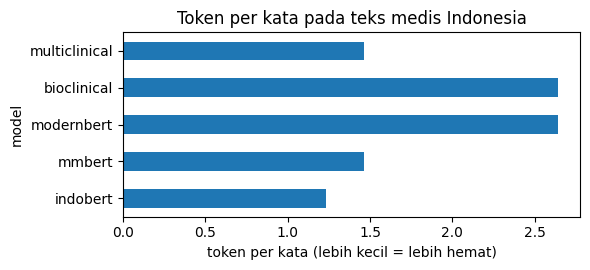

In [ ]:
from transformers import PreTrainedTokenizerFast

SPECIAL_KEYS = ["bos_token", "eos_token", "unk_token", "sep_token", "pad_token", "cls_token", "mask_token"]

def _tok_manual(path, **kw):
    # Untuk checkpoint yang disimpan dengan transformers v5: baca tokenizer.json langsung,
    # ambil token khusus dari config, abaikan field v5 seperti extra_special_tokens (list).
    get = (lambda f: os.path.join(path, f)) if os.path.isdir(path) else (lambda f: hf_hub_download(path, f))
    cfg = jload(get("tokenizer_config.json"))
    try:
        stm = jload(get("special_tokens_map.json"))
    except Exception:
        stm = {}
    keep = {}
    for k in SPECIAL_KEYS:
        v = stm.get(k, cfg.get(k))
        if isinstance(v, dict):
            v = v.get("content")
        if v is not None:
            keep[k] = v
    if isinstance(cfg.get("model_max_length"), int):
        keep["model_max_length"] = cfg["model_max_length"]
    return PreTrainedTokenizerFast(tokenizer_file=get("tokenizer.json"), **keep, **kw)

_TOK = {}
def load_tok(path, key=None):
    # Tokenizer BPE byte-level (ModernBERT) butuh add_prefix_space=True untuk input yang sudah dipecah per kata (NER).
    prefix = key in CFG["prefix_space_models"]
    k = (path, prefix)
    if k not in _TOK:
        kw = {"add_prefix_space": True} if prefix else {}
        try:
            tok = AutoTokenizer.from_pretrained(path, **kw)
        except (ValueError, AttributeError) as e:
            print(f"[load_tok] {path}: {type(e).__name__}: {e} -> muat manual dari tokenizer.json")
            tok = _tok_manual(path, **kw)
        assert tok.mask_token is not None, f"{path}: mask_token kosong"
        _TOK[k] = tok
    return _TOK[k]

CONTOH_KALIMAT = "Pasien mengalami diare dan nyeri perut bagian bawah sejak kemarin, disertai demam."
sample = TEXTS["test_medis"][:300]
n_word = np.array([len(t.split()) for t in sample])
rows = []
for key in CFG["run_models"]:
    tok = load_tok(CFG["models"][key], key)
    n_tok = np.array([len(tok(t, add_special_tokens=False)["input_ids"]) for t in sample])
    pecahan = tok.tokenize(CONTOH_KALIMAT)
    rows.append({"model": key, "vocab": len(tok), "token_per_kata": round(n_tok.sum() / n_word.sum(), 3),
                 "token_per_dokumen": round(n_tok.mean(), 1), "dokumen_>510_token_%": round(100 * np.mean(n_tok > 510), 1),
                 "contoh_jumlah_token": len(pecahan), "contoh_pecahan": " | ".join(pecahan)})
TOK_STATS = pd.DataFrame(rows)
TOK_STATS.to_csv(f"{RES}/tokenizer.csv", index=False)
display(TOK_STATS)

ax = TOK_STATS.set_index("model")["token_per_kata"].plot.barh(figsize=(6, 2.8), title="Token per kata pada teks medis Indonesia")
ax.set_xlabel("token per kata (lebih kecil = lebih hemat)")
plt.tight_layout(); plt.savefig(f"{REP}/figures/tokenizer_token_per_kata.png", dpi=150); plt.show()

**Interpretasi:** `[Isi: tokenizer mana yang paling hemat dan paling boros? Berapa kali lipat? Lihat contoh pecahan: kata medis mana yang dipotong-potong oleh tokenizer bahasa Inggris? Dampaknya: lebih banyak blok saat DAPT, training lebih lama, dan dokumen lebih cepat melewati 512 token.]`

### 2.2 Info model dan cek head MLM

Untuk setiap checkpoint dicatat: jumlah parameter total, parameter embedding (vocab × hidden), parameter badan transformer, panjang posisi maksimum, dan apakah head MLM ikut tersimpan. Head MLM yang hilang (seperti DeBERTa-v3 di CP1, loss awal 16,59) membuat MLM loss `before` tidak bermakna.

Sel ini juga menjalankan **fill-mask** pada satu kalimat. Kalau tebakan teratasnya masuk akal, head MLM bekerja.

In [ ]:
def load_mlm(path):
    # Untuk keluarga ModernBERT, sparse_prediction=True membuat logit hanya dihitung di token yang ditutup (hemat memori,
    # penting untuk mmBERT yang vocab-nya 256 ribu).
    cfg = AutoConfig.from_pretrained(path)
    if getattr(cfg, "model_type", "") == "modernbert":
        cfg.sparse_prediction = True
    return AutoModelForMaskedLM.from_pretrained(path, config=cfg)

info_rows = []
for key in CFG["run_models"]:
    repo = CFG["models"][key]
    tok = load_tok(repo, key)
    model, info = AutoModelForMaskedLM.from_pretrained(repo, output_loading_info=True)
    total = sum(p.numel() for p in model.parameters())
    emb = model.get_input_embeddings().weight.numel()
    head_missing = [k for k in info["missing_keys"] if any(s in k for s in ("pred", "lm_head", "cls.", "head", "decoder"))]
    fm = pipeline("fill-mask", model=model, tokenizer=tok, device=0 if HAS_GPU else -1)
    tebak = fm(f"Pasien mengalami {tok.mask_token} dan demam sejak kemarin.", top_k=3)
    info_rows.append({"model": key, "checkpoint": repo, "param_juta": round(total / 1e6, 1),
                      "embedding_juta": round(emb / 1e6, 1), "badan_juta": round((total - emb) / 1e6, 1),
                      "max_posisi": getattr(model.config, "max_position_embeddings", None),
                      "head_MLM_hilang": len(head_missing) > 0,
                      "fill_mask_top3": ", ".join(t["token_str"].strip() for t in tebak)})
    del model, fm; free()
MODEL_INFO = pd.DataFrame(info_rows)
MODEL_INFO.to_csv(f"{RES}/model_info.csv", index=False)
MODEL_INFO

pytorch_model.bin:   0%|          | 0.00/498M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/498M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.23G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.23G [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/616M [00:00<?, ?B/s]

,model,checkpoint,param_juta,embedding_juta,badan_juta,max_posisi,head_MLM_hilang,fill_mask_top3
0,indobert,indobenchmark/indobert-base-p1,124.5,38.4,86.1,512,True,"sana, ada, kampung"
1,mmbert,jhu-clsp/mmBERT-base,307.8,196.6,111.2,8192,False,"flu, panas, sakit"
2,modernbert,answerdotai/ModernBERT-base,149.7,38.7,111.0,8192,False,",, kan, ini"
3,bioclinical,thomas-sounack/BioClinical-ModernBERT-base,149.7,38.7,111.0,8192,False,",, yang, dan"
4,multiclinical,YLab-Open/MultiClinicalBERT,307.8,196.6,111.2,8192,False,"panas, flu, malaise"


**Interpretasi:** `[Isi: apakah badan transformer ketiga keluarga hampir sama besar (sekitar 86 sampai 111 juta) walaupun total parameternya berbeda karena embedding? Apakah ada head MLM yang hilang? Tebakan fill-mask mana yang masuk akal (misalnya "diare", "batuk", "mual") dan mana yang tidak? Model bahasa Inggris diduga menebak kata yang tidak nyambung.]`

<a id="bagian-3"></a>
## 3. Data NER (bioner_id)

### 3.1 Baca dan ringkas

bioner_id sudah dibaca di bagian 1.5 (`NER_RAW`). Setiap contoh adalah satu jawaban dokter yang sudah dipecah per token, dengan label BIO untuk dua jenis entitas:

- `DISO`: penyakit atau gangguan (contoh: diare, HIV, batu ginjal)
- `ANAT`: anatomi (contoh: ginjal, saluran kemih, paru-paru)

Sel ini membuat daftar label dari data train dan menghitung jumlah dokumen, token, dan entitas per split. Label yang tidak ada di train akan dilaporkan.

In [ ]:
LABELS = ["O"] + sorted({t for _, tags in NER_RAW["train"] for t in tags} - {"O"})
L2I = {l: i for i, l in enumerate(LABELS)}
print("Label:", LABELS)

rows = []
for split, docs in NER_RAW.items():
    unknown = Counter(t for _, tags in docs for t in tags if t not in L2I)
    if unknown:
        print(f"PERINGATAN {split}: label tidak dikenal {dict(unknown)} -> dianggap O")
    ent = Counter(t[2:] for _, tags in docs for t in tags if t.startswith("B-"))
    rows.append({"split": split, "dokumen": len(docs), "token": sum(len(t) for t, _ in docs),
                 "token_per_dokumen_median": int(np.median([len(t) for t, _ in docs])),
                 **{f"entitas_{k}": v for k, v in sorted(ent.items())},
                 "persen_token_O": round(100 * np.mean([t == "O" for _, tags in docs for t in tags]), 1)})
NER_STATS = pd.DataFrame(rows)
NER_STATS.to_csv(f"{RES}/ner_stats.csv", index=False)
NER_STATS

Label: ['O', 'B-ANAT', 'B-DISO', 'I-ANAT', 'I-DISO']


,split,dokumen,token,token_per_dokumen_median,entitas_ANAT,entitas_DISO,persen_token_O
0,train,1948,488479,231,9346,35922,84.3
1,validation,260,64990,224,1212,4616,84.7
2,test,391,105341,250,2563,6296,85.9


**Interpretasi:** `[Isi: perbandingan jumlah DISO dan ANAT, proporsi token O (biasanya di atas 85%, artinya data sangat tidak seimbang), dan apakah distribusi entitas train, validation, dan test mirip.]`

### 3.2 Cek konsistensi label

Dari preview, ada label yang janggal (misalnya "nyeri" B-DISO lalu "tenggorokan" B-DISO lagi). Label **tidak diubah**, terutama di test, karena itu standar resminya. Sel ini hanya menghitung dua pola janggal untuk dicatat sebagai keterbatasan:

- `I` tanpa `B` di depannya (misalnya `O I-DISO`)
- `B` berurutan dengan tipe sama (`B-ANAT B-ANAT`), yang mungkin seharusnya `B I`

In [ ]:
def cek_label(tags):
    janggal, prev = Counter(), "O"
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]:
            janggal["I tanpa B"] += 1
        if t.startswith("B-") and prev == t:
            janggal["B berurutan tipe sama"] += 1
        prev = t
    return janggal

rows = []
for split, docs in NER_RAW.items():
    tot = Counter()
    for _, tags in docs:
        tot += cek_label(tags)
    n_ent = sum(t.startswith("B-") for _, tags in docs for t in tags)
    rows.append({"split": split, "jumlah_entitas_B": n_ent, **dict(tot),
                 "persen_janggal": round(100 * sum(tot.values()) / max(1, n_ent), 2)})
pd.DataFrame(rows).fillna(0)

,split,jumlah_entitas_B,B berurutan tipe sama,I tanpa B,persen_janggal
0,train,45268,5680,40,12.64
1,validation,5828,697,3,12.01
2,test,8859,736,15,8.48


### 3.3 Potong dokumen per kalimat untuk setiap tokenizer

Satu contoh bioner_id adalah satu jawaban dokter, dan sebagian bisa lebih dari 512 token. Kalau dipotong begitu saja di token ke-512, sisa dokumen hilang dan entitas di ujungnya tidak pernah dinilai.

Solusinya: dokumen dipecah per kalimat (berakhir dengan `.`, `!`, atau `?`), lalu kalimat-kalimat disusun menjadi potongan yang muat dalam batas token **tokenizer model itu**. Kalau satu kalimat saja sudah terlalu panjang, kalimat itu dipotong per kata. Dengan cara ini:

- semua kata di test ikut dinilai oleh semua model,
- entitas tidak terbelah di tengah, karena entitas tidak melewati akhir kalimat,
- jumlah potongan bisa berbeda antar model (tokenizer boros menghasilkan lebih banyak potongan), tapi kata yang dinilai sama.

Ini sedikit berbeda dari rencana awal (jendela dengan overlap): pemotongan per kalimat lebih sederhana dan tidak menilai kata yang sama dua kali.

In [ ]:
def special_wrap(tok):
    # Cari token khusus di depan dan belakang (misal [CLS] ... [SEP]) secara otomatis untuk tokenizer apa pun.
    plain = tok("halo", add_special_tokens=False)["input_ids"]
    full = tok("halo")["input_ids"]
    for i in range(len(full) - len(plain) + 1):
        if full[i:i + len(plain)] == plain:
            return full[:i], full[i + len(plain):]
    return [], []

SENT_END = {".", "!", "?"}

def chunk_doc(tokens, tags, tok, budget):
    # Susun kalimat menjadi potongan yang jumlah subword-nya <= budget.
    enc = tok(tokens, is_split_into_words=True, add_special_tokens=False)
    n_sub = Counter(w for w in enc.word_ids() if w is not None)
    sents, cur = [], []
    for i, t in enumerate(tokens):
        cur.append(i)
        if t in SENT_END:
            sents.append(cur); cur = []
    if cur:
        sents.append(cur)
    chunks, buf, buf_n = [], [], 0
    def flush():
        nonlocal buf, buf_n
        if buf:
            chunks.append(buf)
        buf, buf_n = [], 0
    for s in sents:
        sn = sum(n_sub[i] for i in s)
        if sn > budget:                       # kalimat terlalu panjang: potong per kata
            flush()
            for i in s:
                if buf_n + n_sub[i] > budget:
                    carry = []
                    if tags[i].startswith("I-"):  # jangan belah entitas: pindahkan entitas utuh ke potongan berikutnya
                        j = len(buf) - 1
                        while j > 0 and not tags[buf[j]].startswith("B-"):
                            j -= 1
                        if j > 0:
                            carry, buf = buf[j:], buf[:j]
                    flush()
                    buf, buf_n = carry, sum(n_sub[x] for x in carry)
                buf.append(i); buf_n += n_sub[i]
            flush()
        elif buf_n + sn > budget:
            flush(); buf, buf_n = list(s), sn
        else:
            buf.extend(s); buf_n += sn
    flush()
    return [([tokens[i] for i in c], [tags[i] for i in c]) for c in chunks]

_NER_DS = {}
def ner_dataset(key):
    # DatasetDict potongan untuk satu model (tokenizer sama untuk before, dapt1, dapt2).
    if key in _NER_DS:
        return _NER_DS[key]
    tok = load_tok(CFG["models"][key], key)
    pre, post = special_wrap(tok)
    budget = CFG["max_len"] - len(pre) - len(post)
    dd = {}
    for split, docs in NER_RAW.items():
        rows = {"tokens": [], "ner_tags": [], "doc_id": []}
        for d, (toks, tags) in enumerate(docs):
            for ct, cg in chunk_doc(toks, tags, tok, budget):
                rows["tokens"].append(ct); rows["ner_tags"].append([L2I.get(t, 0) for t in cg]); rows["doc_id"].append(d)
        dd[split] = Dataset.from_dict(rows)
    _NER_DS[key] = DatasetDict(dd)
    return _NER_DS[key]

rows = []
for key in CFG["run_models"]:
    dd = ner_dataset(key)
    rows.append({"model": key, **{f"potongan_{s}": len(dd[s]) for s in dd},
                 "kata_test": sum(len(t) for t in dd["test"]["tokens"])})
CHUNK_STATS = pd.DataFrame(rows)
CHUNK_STATS

,model,potongan_train,potongan_validation,potongan_test,kata_test
0,indobert,2022,270,413,105341
1,mmbert,2099,280,428,105341
2,modernbert,3131,415,658,105341
3,bioclinical,3131,415,658,105341
4,multiclinical,2099,280,428,105341


**Cek:** kolom `kata_test` harus sama untuk semua model (semua kata test ikut dinilai). `[Isi: model mana yang menghasilkan potongan paling banyak, dan apakah itu sejalan dengan token per kata di bagian 2.1?]`

<a id="bagian-4"></a>
## 4. Loop per Model

Setiap model melewati urutan yang sama:

```
before ──DAPT tahap 1──▶ dapt1 ──DAPT tahap 2──▶ dapt2
   │                       │                       │
evaluasi                evaluasi                evaluasi        (MLM loss medis + Wikipedia, NER 3 seed)
```

Model klinis (BioClinical, MultiClinical) tetap menjalani kedua tahap DAPT, tapi hanya dievaluasi di `before` dan `dapt2` supaya waktu muat.

| Aspek | DAPT tahap 1 | DAPT tahap 2 |
|---|---|---|
| Data | `tahap1_train` (medis + Wikipedia) | `tahap2_train` (medis saja) |
| Masking | 30% keluarga ModernBERT, 15% IndoBERT | 15% semua model |
| Learning rate | 5e-5 konstan setelah warmup 6% | 2e-5 menurun 1−sqrt, tanpa warmup |
| Durasi | 1 epoch | 0,5 epoch |
| Batch efektif | 32 blok × 512 token | sama |
| Optimizer | AdamW, β₂ = 0,98, ε = 1e-6, weight decay 1e-5 | sama |

| Aspek NER | Pengaturan |
|---|---|
| Arsitektur | encoder + linear classifier per token |
| Label | BIO, subword pertama tiap kata diberi label, sisanya diabaikan (`-100`) |
| Epoch | maksimal 10, early stopping patience 3 berdasarkan F1 validation |
| Learning rate | dipilih dari {5e-5, 1e-4} pada validation dengan model `before` seed 42, lalu dipakai untuk semua tahap dan seed model itu |
| Seed | 42, 43, 44; dilaporkan median dan std |
| Metrik | F1 entitas seqeval, precision, recall, F1 per jenis entitas |

### 4.0 Fungsi-fungsi

Sel berikut hanya **mendefinisikan** fungsi, belum menjalankan apa pun:

- `build_blocks`: teks → disambung → dipotong blok 512 token (dengan token khusus tiap tokenizer).
- `get_blocks`: sama, tapi hasilnya disimpan ke Drive supaya tokenisasi jutaan kata tidak diulang.
- `mlm_eval_loss` dan `eval_mlm`: MLM loss di `test_medis` dan `wiki_ujilupa`. Posisi mask dikunci dengan seed supaya `before` dan `after` dinilai pada soal yang sama.
- `run_dapt`: satu tahap DAPT, lalu simpan checkpoint, log loss, dan biaya (jam GPU, token per detik, VRAM puncak).
- `ner_run` dan `select_lr`: satu run fine-tuning NER dan pemilihan learning rate.

In [ ]:
def build_blocks(text_list, tok, max_len=CFG["max_len"]):
    pre, post = special_wrap(tok)
    body = max_len - len(pre) - len(post)
    ds = Dataset.from_dict({"text": list(text_list)})
    ds = ds.map(lambda b: tok(b["text"], add_special_tokens=False), batched=True, remove_columns=["text"], desc="tokenisasi")
    def group(b):
        ids = list(chain.from_iterable(b["input_ids"]))
        n = (len(ids) // body) * body
        blocks = [pre + ids[i:i + body] + post for i in range(0, n, body)]
        return {"input_ids": blocks, "attention_mask": [[1] * max_len for _ in blocks]}
    return ds.map(group, batched=True, batch_size=1000, remove_columns=ds.column_names, desc="potong blok")

_BLOCKS = {}
def get_blocks(key, split):
    k = (key, split)
    if k not in _BLOCKS:
        path = f"{DATA}/blocks/{key}_{split}"
        if os.path.exists(path):
            _BLOCKS[k] = load_from_disk(path)
        else:
            _BLOCKS[k] = build_blocks(TEXTS[split], load_tok(CFG["models"][key], key))
            _BLOCKS[k].save_to_disk(path)
    return _BLOCKS[k]

@torch.no_grad()
def mlm_eval_loss(model, tok, blocks, prob=CFG["eval_mlm_prob"], bs=CFG["eval_batch"], max_blocks=CFG["eval_max_blocks"], seed=CFG["seed"]):
    # Rata-rata cross-entropy di token yang ditutup. Memakai outputs.loss supaya jalan juga dengan sparse_prediction.
    model.eval()
    coll = DataCollatorForLanguageModeling(tok, mlm_probability=prob)
    sub = blocks.select(range(min(len(blocks), max_blocks)))
    torch.manual_seed(seed)
    tot_loss, tot_tok = 0.0, 0
    for i in range(0, len(sub), bs):
        batch = coll([sub[j] for j in range(i, min(i + bs, len(sub)))])
        batch = {k: v.to(model.device) for k, v in batch.items()}
        n = int((batch["labels"] != -100).sum())
        if n == 0:
            continue
        with torch.autocast("cuda", dtype=DTYPE, enabled=HAS_GPU):
            out = model(**batch)
        tot_loss += out.loss.float().item() * n
        tot_tok += n
    return tot_loss / tot_tok

def eval_mlm(key, stage):
    out = f"{RES}/mlm_{key}_{stage}.json"
    if os.path.exists(out):
        return jload(out)
    path = model_path(key, stage)
    if stage != "before" and not has_ckpt(path):
        print(f"[belum ada] {key}-{stage}"); return None
    tok = load_tok(CFG["models"][key], key)
    model = load_mlm(path).to(DEVICE)
    res = {"model": key, "stage": stage,
           "medis_test_loss": round(mlm_eval_loss(model, tok, get_blocks(key, "test_medis")), 4),
           "wiki_loss": round(mlm_eval_loss(model, tok, get_blocks(key, "wiki_ujilupa")), 4)}
    jsave(res, out); del model; free()
    print(res)
    return res

def run_dapt(key, stage):
    out_dir, stats_path = model_path(key, stage), f"{RES}/dapt_{key}_{stage}.json"
    if os.path.exists(stats_path) and has_ckpt(out_dir):
        print(f"[lewati] {key}-{stage} sudah ada"); return jload(stats_path)
    src = CFG["models"][key] if stage == "dapt1" else model_path(key, "dapt1")
    if stage == "dapt2" and not has_ckpt(src):
        print(f"[tunggu] {key}-dapt1 belum ada"); return None
    tok = load_tok(CFG["models"][key], key)
    blocks = get_blocks(key, "tahap1_train" if stage == "dapt1" else "tahap2_train")
    model = load_mlm(src)
    bs = CFG["train_batch"].get(key, CFG["train_batch"]["default"])
    accum = max(1, CFG["eff_batch"] // bs)
    prob = mlm_prob(key, stage)
    epochs, lr = (CFG["stage1_epochs"], CFG["stage1_lr"]) if stage == "dapt1" else (CFG["stage2_epochs"], CFG["stage2_lr"])
    steps = max(1, int(len(blocks) * epochs / (bs * accum)))
    args = TrainingArguments(
        output_dir=f"{TMP}/{key}-{stage}", max_steps=steps, per_device_train_batch_size=bs,
        gradient_accumulation_steps=accum, learning_rate=lr, weight_decay=CFG["weight_decay"],
        adam_beta2=CFG["adam_beta2"], adam_epsilon=CFG["adam_eps"],
        lr_scheduler_type="constant_with_warmup", warmup_steps=int(CFG["warmup_frac"] * steps) if stage == "dapt1" else 0,
        logging_steps=max(1, steps // 40), save_strategy="no", report_to="none",
        bf16=BF16, fp16=HAS_GPU and not BF16, seed=CFG["seed"], dataloader_num_workers=2)
    optimizers = (None, None)
    if stage == "dapt2":   # jadwal 1 - sqrt(t/T) seperti fase 2 paper
        opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, CFG["adam_beta2"]), eps=CFG["adam_eps"], weight_decay=CFG["weight_decay"])
        sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(0.0, 1 - math.sqrt(min(s, steps) / steps)))
        optimizers = (opt, sched)
    trainer = Trainer(model=model, args=args, train_dataset=blocks, optimizers=optimizers,
                      data_collator=DataCollatorForLanguageModeling(tok, mlm_probability=prob))
    if HAS_GPU:
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); out = trainer.train(); secs = time.time() - t0
    n_tok = steps * bs * accum * CFG["max_len"]
    model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
    pd.DataFrame(trainer.state.log_history).to_csv(f"{RES}/dapt_log_{key}_{stage}.csv", index=False)
    stats = {"model": key, "stage": stage, "mlm_prob": prob, "lr": lr, "steps": steps, "batch": bs, "grad_accum": accum,
             "blok_tersedia": len(blocks), "token_dilatih": n_tok, "detik": round(secs, 1), "jam_gpu": round(secs / 3600, 3),
             "token_per_detik": round(n_tok / secs, 1),
             "peak_vram_GB": round(torch.cuda.max_memory_allocated() / 1e9, 2) if HAS_GPU else None,
             "train_loss": round(out.training_loss, 4), "gpu": GPU_NAME}
    jsave(stats, stats_path); shutil.rmtree(f"{TMP}/{key}-{stage}", ignore_errors=True)
    del model, trainer; free()
    print(stats)
    return stats

def ner_metrics_fn(p):
    preds, labs = np.argmax(p.predictions, axis=2), p.label_ids
    y_true = [[LABELS[l] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(preds, labs)]
    y_pred = [[LABELS[pp] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(preds, labs)]
    return {"f1": seq_f1(y_true, y_pred), "precision": seq_p(y_true, y_pred), "recall": seq_r(y_true, y_pred)}

def tokenize_ner(dd, tok):
    def align(b):
        enc = tok(b["tokens"], truncation=True, is_split_into_words=True, max_length=CFG["max_len"])
        all_lab = []
        for i, tags in enumerate(b["ner_tags"]):
            prev, lab = None, []
            for w in enc.word_ids(batch_index=i):
                lab.append(-100 if w is None or w == prev else tags[w]); prev = w
            all_lab.append(lab)
        enc["labels"] = all_lab
        return enc
    return dd.map(align, batched=True, remove_columns=dd["train"].column_names)

def ner_run(key, stage, lr, seed, keep_preds=False, save_to=None):
    tag = f"{key}_{stage}_lr{lr:g}_s{seed}"
    out = f"{save_to}_result.json" if save_to else f"{RES}/ner/{tag}.json"
    if os.path.exists(out):
        return jload(out)
    path = model_path(key, stage)
    if stage != "before" and not has_ckpt(path):
        print(f"[belum ada] {key}-{stage}"); return None
    tok = load_tok(CFG["models"][key], key)
    tds = tokenize_ner(ner_dataset(key), tok)
    set_seed(seed)
    model = AutoModelForTokenClassification.from_pretrained(
        path, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=L2I)
    args = TrainingArguments(
        output_dir=f"{TMP}/{tag}", num_train_epochs=CFG["ner_epochs"], learning_rate=lr,
        per_device_train_batch_size=CFG["ner_batch"], per_device_eval_batch_size=32, weight_decay=CFG["ner_weight_decay"],
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        logging_strategy="epoch", report_to="none", seed=seed, data_seed=seed,
        bf16=BF16, fp16=HAS_GPU and not BF16)
    trainer = Trainer(model=model, args=args, train_dataset=tds["train"], eval_dataset=tds["validation"],
                      data_collator=DataCollatorForTokenClassification(tok), compute_metrics=ner_metrics_fn,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG["ner_patience"])])
    t0 = time.time(); trainer.train(); secs = time.time() - t0
    val = trainer.evaluate(tds["validation"])
    pred = trainer.predict(tds["test"])
    p_ids, l_ids = np.argmax(pred.predictions, axis=2), pred.label_ids
    y_true = [[LABELS[l] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(p_ids, l_ids)]
    y_pred = [[LABELS[pp] for (pp, l) in zip(pr, lb) if l != -100] for pr, lb in zip(p_ids, l_ids)]
    rep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    res = {"model": key, "stage": stage, "lr": lr, "seed": seed,
           "val_f1": round(val["eval_f1"], 4), "test_f1": round(seq_f1(y_true, y_pred), 4),
           "test_precision": round(seq_p(y_true, y_pred), 4), "test_recall": round(seq_r(y_true, y_pred), 4),
           "per_type": {k: round(v["f1-score"], 4) for k, v in rep.items() if k not in ("micro avg", "macro avg", "weighted avg")},
           "epochs_trained": round(trainer.state.epoch, 1), "detik": round(secs, 1)}
    if keep_preds:
        res["test_true"], res["test_pred"] = y_true, y_pred
    if save_to:
        trainer.save_model(save_to); tok.save_pretrained(save_to)
    jsave(res, out)
    shutil.rmtree(f"{TMP}/{tag}", ignore_errors=True); del model, trainer; free()
    print({k: res[k] for k in ("model", "stage", "lr", "seed", "val_f1", "test_f1")})
    return res

def select_lr(key):
    # LR dipilih di validation memakai model 'before' seed 42; dipakai untuk semua tahap dan seed model itu.
    out = f"{RES}/ner/lr_{key}.json"
    if os.path.exists(out):
        return jload(out)["lr"]
    scores = {lr: ner_run(key, "before", lr, CFG["seed"], keep_preds=True)["val_f1"] for lr in CFG["ner_lr_grid"]}
    best = max(scores, key=scores.get)
    jsave({"lr": best, "val_f1": {str(k): v for k, v in scores.items()}}, out)
    return best

def evaluate_stage(key, stage):
    # Evaluasi lengkap satu titik: MLM loss + NER semua seed.
    if stage not in eval_stages(key):
        return
    eval_mlm(key, stage)
    lr = select_lr(key)
    for seed in CFG["ner_seeds"]:
        ner_run(key, stage, lr, seed, keep_preds=(seed == CFG["seed"]))
print("Fungsi siap.")

Fungsi siap.


### 4a. Baseline (`before`)

Untuk setiap model: MLM loss checkpoint asli, pemilihan learning rate NER, lalu fine-tuning NER dengan 3 seed. Sel yang sama aman dijalankan ulang; run yang sudah ada dilewati.

In [ ]:
if CFG["RUN_BASELINE"]:
    for key in CFG["run_models"]:
        print(f"\n===== {key}: before =====")
        evaluate_stage(key, "before")


===== indobert: before =====

===== mmbert: before =====

===== modernbert: before =====


Map:   0%|          | 0/3131 [00:00<?, ? examples/s]

Map:   0%|          | 0/415 [00:00<?, ? examples/s]

Map:   0%|          | 0/658 [00:00<?, ? examples/s]

{'loss': 0.2813, 'grad_norm': 1.1679116487503052, 'learning_rate': 4.502551020408164e-05, 'epoch': 1.0}
{'eval_loss': 0.15838898718357086, 'eval_f1': 0.6501521077792264, 'eval_precision': 0.6591469862530842, 'eval_recall': 0.641399416909621, 'eval_runtime': 3.2759, 'eval_samples_per_second': 126.683, 'eval_steps_per_second': 3.968, 'epoch': 1.0}
{'loss': 0.1427, 'grad_norm': 0.8949838280677795, 'learning_rate': 4.002551020408164e-05, 'epoch': 2.0}
{'eval_loss': 0.12375789880752563, 'eval_f1': 0.7031947483588622, 'eval_precision': 0.7180908115838398, 'eval_recall': 0.6889041330818042, 'eval_runtime': 1.5362, 'eval_samples_per_second': 270.156, 'eval_steps_per_second': 8.463, 'epoch': 2.0}
{'loss': 0.1019, 'grad_norm': 0.6871192455291748, 'learning_rate': 3.502551020408164e-05, 'epoch': 3.0}
{'eval_loss': 0.102742999792099, 'eval_f1': 0.7651294359677696, 'eval_precision': 0.7648671808054841, 'eval_recall': 0.765391871034128, 'eval_runtime': 1.5402, 'eval_samples_per_second': 269.447, 'ev

Map:   0%|          | 0/3131 [00:00<?, ? examples/s]

... (53 outputs left out)

Map:   0%|          | 0/2099 [00:00<?, ? examples/s]

Map:   0%|          | 0/280 [00:00<?, ? examples/s]

Map:   0%|          | 0/428 [00:00<?, ? examples/s]

{'loss': 0.2139, 'grad_norm': 2.4569835662841797, 'learning_rate': 9.007575757575759e-05, 'epoch': 1.0}
{'eval_loss': 0.12584279477596283, 'eval_f1': 0.725342768686422, 'eval_precision': 0.7489952502740227, 'eval_recall': 0.7031383982164294, 'eval_runtime': 1.1393, 'eval_samples_per_second': 245.771, 'eval_steps_per_second': 7.9, 'epoch': 1.0}
{'loss': 0.1231, 'grad_norm': 1.0322580337524414, 'learning_rate': 8.007575757575759e-05, 'epoch': 2.0}
{'eval_loss': 0.11569442600011826, 'eval_f1': 0.7128269437477606, 'eval_precision': 0.7461091318207388, 'eval_recall': 0.6823872406105299, 'eval_runtime': 1.1512, 'eval_samples_per_second': 243.223, 'eval_steps_per_second': 7.818, 'epoch': 2.0}
{'loss': 0.0916, 'grad_norm': 0.8882282376289368, 'learning_rate': 7.007575757575759e-05, 'epoch': 3.0}
{'eval_loss': 0.09366743266582489, 'eval_f1': 0.7827843653930611, 'eval_precision': 0.8023046453006842, 'eval_recall': 0.7641913908420511, 'eval_runtime': 1.1492, 'eval_samples_per_second': 243.655, 'e

### 4b. DAPT tahap 1 + evaluasi `dapt1`

Tahap 1 melatih model dengan campuran teks medis dan Wikipedia, LR konstan setelah warmup. Setelah selesai, model dievaluasi kalau `dapt1` ada di `eval_stages` model itu (default: hanya tiga model inti).

In [21]:
if CFG["RUN_DAPT1"]:
    for key in CFG["run_models"]:
        print(f"\n===== {key}: DAPT tahap 1 =====")
        run_dapt(key, "dapt1")
        evaluate_stage(key, "dapt1")


===== indobert: DAPT tahap 1 =====


tokenisasi:   0%|          | 0/86335 [00:00<?, ? examples/s]

potong blok:   0%|          | 0/86335 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/37653 [00:00<?, ? examples/s]

{'loss': 8.9934, 'grad_norm': 1.6381884813308716, 'learning_rate': 2e-05, 'epoch': 0.02464414701508392}
{'loss': 7.2432, 'grad_norm': 1.7278050184249878, 'learning_rate': 4.0714285714285717e-05, 'epoch': 0.04928829403016784}
{'loss': 6.7977, 'grad_norm': 2.3315317630767822, 'learning_rate': 5e-05, 'epoch': 0.07393244104525175}
{'loss': 6.4761, 'grad_norm': 1.7229231595993042, 'learning_rate': 5e-05, 'epoch': 0.09857658806033567}
{'loss': 6.2762, 'grad_norm': 2.145203113555908, 'learning_rate': 5e-05, 'epoch': 0.12322073507541959}
{'loss': 6.0944, 'grad_norm': 1.7102969884872437, 'learning_rate': 5e-05, 'epoch': 0.1478648820905035}
{'loss': 5.9842, 'grad_norm': 1.8314720392227173, 'learning_rate': 5e-05, 'epoch': 0.17250902910558744}
{'loss': 5.8818, 'grad_norm': 2.0065717697143555, 'learning_rate': 5e-05, 'epoch': 0.19715317612067135}
{'loss': 5.7929, 'grad_norm': 2.054262638092041, 'learning_rate': 5e-05, 'epoch': 0.22179732313575526}
{'loss': 5.6551, 'grad_norm': 2.073963165283203, '

Map:   0%|          | 0/2022 [00:00<?, ? examples/s]

... (48 outputs left out)

tokenisasi:   0%|          | 0/86335 [00:00<?, ? examples/s]

potong blok:   0%|          | 0/86335 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/44326 [00:00<?, ? examples/s]

{'loss': 1.9695, 'grad_norm': 4.35521936416626, 'learning_rate': 1.9879518072289157e-05, 'epoch': 0.02454430608193467}
{'loss': 1.8002, 'grad_norm': 4.264841079711914, 'learning_rate': 4.036144578313254e-05, 'epoch': 0.04908861216386934}
{'loss': 1.7528, 'grad_norm': 3.803217887878418, 'learning_rate': 5e-05, 'epoch': 0.07363291824580401}
{'loss': 1.6943, 'grad_norm': 3.4109623432159424, 'learning_rate': 5e-05, 'epoch': 0.09817722432773868}
{'loss': 1.6334, 'grad_norm': 3.5555403232574463, 'learning_rate': 5e-05, 'epoch': 0.12272153040967335}
{'loss': 1.626, 'grad_norm': 3.319767951965332, 'learning_rate': 5e-05, 'epoch': 0.14726583649160802}
{'loss': 1.588, 'grad_norm': 3.4383442401885986, 'learning_rate': 5e-05, 'epoch': 0.17181014257354268}
{'loss': 1.5853, 'grad_norm': 3.943675994873047, 'learning_rate': 5e-05, 'epoch': 0.19635444865547735}
{'loss': 1.5729, 'grad_norm': 2.990100860595703, 'learning_rate': 5e-05, 'epoch': 0.22089875473741202}
{'loss': 1.567, 'grad_norm': 3.559014558

### 4c. DAPT tahap 2 + evaluasi `dapt2`

Tahap 2 melanjutkan dari `dapt1` dengan teks medis saja dan LR yang menurun 1−sqrt. Semua model dievaluasi di titik ini.

In [22]:
if CFG["RUN_DAPT2"]:
    for key in CFG["run_models"]:
        print(f"\n===== {key}: DAPT tahap 2 =====")
        run_dapt(key, "dapt2")
        evaluate_stage(key, "dapt2")


===== indobert: DAPT tahap 2 =====


tokenisasi:   0%|          | 0/60765 [00:00<?, ? examples/s]

potong blok:   0%|          | 0/60765 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/29309 [00:00<?, ? examples/s]

{'loss': 2.4466, 'grad_norm': 2.350606679916382, 'learning_rate': 1.7041497806362265e-05, 'epoch': 0.012008733624454149}
{'loss': 2.4109, 'grad_norm': 2.2637882232666016, 'learning_rate': 1.571272301075677e-05, 'epoch': 0.024017467248908297}
{'loss': 2.396, 'grad_norm': 2.226592779159546, 'learning_rate': 1.470767038675502e-05, 'epoch': 0.036026200873362446}
{'loss': 2.3901, 'grad_norm': 2.271209716796875, 'learning_rate': 1.3865119276793968e-05, 'epoch': 0.048034934497816595}
{'loss': 2.4092, 'grad_norm': 2.15628981590271, 'learning_rate': 1.3125062164593762e-05, 'epoch': 0.060043668122270744}
{'loss': 2.3895, 'grad_norm': 2.232611894607544, 'learning_rate': 1.2457269791817062e-05, 'epoch': 0.07205240174672489}
{'loss': 2.3815, 'grad_norm': 2.8629095554351807, 'learning_rate': 1.1843972305946316e-05, 'epoch': 0.08406113537117904}
{'loss': 2.4418, 'grad_norm': 2.1680870056152344, 'learning_rate': 1.1273672221437823e-05, 'epoch': 0.09606986899563319}
{'loss': 2.3652, 'grad_norm': 2.1865

Map:   0%|          | 0/2022 [00:00<?, ? examples/s]

... (71 outputs left out)

Map:   0%|          | 0/2099 [00:00<?, ? examples/s]

Map:   0%|          | 0/280 [00:00<?, ? examples/s]

Map:   0%|          | 0/428 [00:00<?, ? examples/s]

{'loss': 0.2046, 'grad_norm': 1.6528537273406982, 'learning_rate': 9.007575757575759e-05, 'epoch': 1.0}
{'eval_loss': 0.12766133248806, 'eval_f1': 0.728580198193458, 'eval_precision': 0.7455132806891601, 'eval_recall': 0.7123992454124507, 'eval_runtime': 1.1338, 'eval_samples_per_second': 246.952, 'eval_steps_per_second': 7.938, 'epoch': 1.0}
{'loss': 0.1156, 'grad_norm': 1.823262333869934, 'learning_rate': 8.007575757575759e-05, 'epoch': 2.0}
{'eval_loss': 0.11030856519937515, 'eval_f1': 0.7320701257304764, 'eval_precision': 0.756727073036793, 'eval_recall': 0.7089693020065169, 'eval_runtime': 1.1374, 'eval_samples_per_second': 246.165, 'eval_steps_per_second': 7.912, 'epoch': 2.0}
{'loss': 0.0867, 'grad_norm': 0.8350135684013367, 'learning_rate': 7.007575757575759e-05, 'epoch': 3.0}
{'eval_loss': 0.08812715113162994, 'eval_f1': 0.7986787204450626, 'eval_precision': 0.8098008108584523, 'eval_recall': 0.7878580003429944, 'eval_runtime': 1.1549, 'eval_samples_per_second': 242.44, 'eval_

<a id="bagian-5"></a>
## 5. Analisis

Semua tabel dibangun dari file di `results/`, jadi hasil partner yang menjalankan model lain di folder Drive yang sama ikut tergabung. Sel analisis tetap jalan walaupun sebagian run belum selesai.

### 5.1 MLM loss medis dan Wikipedia (RQ1, RQ4)

Δ% adalah perubahan dibanding `before`: negatif artinya loss turun (lebih paham). Loss **hanya dibandingkan di dalam model yang sama**, karena tokenizer berbeda membuat soal tebakannya berbeda.

In [31]:
def pivot_change(df, col):
    t = df.pivot_table(index="model", columns="stage", values=col)
    t = t[[s for s in STAGES_ALL if s in t.columns]]
    for st in [s for s in ["dapt1", "dapt2"] if s in t.columns and "before" in t.columns]:
        t[f"Δ%_{st}"] = (100 * (t[st] - t["before"]) / t["before"]).round(2)
    return t

MLM = pd.DataFrame([jload(p) for p in glob.glob(f"{RES}/mlm_*.json")])
if len(MLM):
    MLM_MEDIS = pivot_change(MLM, "medis_test_loss"); MLM_MEDIS.to_csv(f"{REP}/tables/mlm_medis.csv")
    MLM_WIKI = pivot_change(MLM, "wiki_loss"); MLM_WIKI.to_csv(f"{REP}/tables/mlm_wiki.csv")
    print("MLM loss teks medis (test):"); display(MLM_MEDIS)
    print("MLM loss Wikipedia Indonesia (uji lupa, RQ4):"); display(MLM_WIKI)
else:
    print("Belum ada hasil MLM.")

MLM loss teks medis (test):


stage,before,dapt1,dapt2,Δ%_dapt1,Δ%_dapt2
model,,,,,
bioclinical,3.1374,NaN,0.4159,NaN,-86.74
indobert,10.7997,2.2808,2.1552,-78.88,-80.04
mmbert,1.3617,0.8951,0.8579,-34.27,-37.00
modernbert,1.6949,0.4436,0.4112,-73.83,-75.74
multiclinical,1.4810,NaN,0.8631,NaN,-41.72


MLM loss Wikipedia Indonesia (uji lupa, RQ4):


stage,before,dapt1,dapt2,Δ%_dapt1,Δ%_dapt2
model,,,,,
bioclinical,3.2401,NaN,1.2644,NaN,-60.98
indobert,10.7237,3.4827,3.4180,-67.52,-68.13
mmbert,1.3143,1.2862,1.2781,-2.14,-2.75
modernbert,1.8037,1.1479,1.1329,-36.36,-37.19
multiclinical,1.4331,NaN,1.2929,NaN,-9.78


**Interpretasi:** `[Isi: berapa persen MLM loss medis turun di tiap model? Model mana yang turun paling banyak (dugaan: ModernBERT bahasa Inggris, karena sekaligus belajar bahasa)? Untuk Wikipedia: apakah loss naik (tanda lupa), dan apakah lebih kecil dari CP1 (ModernBERT +6,75%, RoBERTa +13,67%) karena Wikipedia dicampur di tahap 1?]`

### 5.2 F1 NER sebelum vs sesudah DAPT (RQ1, RQ2)

Hanya run dengan learning rate terpilih yang dihitung, jadi setiap titik punya tepat 3 seed. Ini memperbaiki masalah CP1, ketika kelompok `before` ikut menghitung satu run tambahan dari pencarian LR.

F1 test (median 3 seed, dalam persen), Δ dalam poin F1:


stage,before,dapt1,dapt2,Δ_dapt1,Δ_dapt2
model,,,,,
bioclinical,87.49,NaN,88.25,NaN,0.76
indobert,81.94,86.32,86.35,4.38,4.41
mmbert,88.48,88.74,88.63,0.26,0.15
modernbert,87.53,87.60,88.28,0.07,0.75
multiclinical,88.75,NaN,88.77,NaN,0.02


Detail (std antar seed, jumlah seed):


test_f1_median  test_f1_std  val_f1_median  n_seed
model         stage                                                     
bioclinical   before          0.8749       0.0014         0.9060       3
              dapt2           0.8825       0.0073         0.9075       3
indobert      before          0.8194       0.0034         0.8568       3
              dapt1           0.8632       0.0012         0.8943       3
              dapt2           0.8635       0.0017         0.8937       3
mmbert        before          0.8848       0.0039         0.9110       3
              dapt1           0.8874       0.0010         0.9133       3
              dapt2           0.8863       0.0012         0.9133       3
modernbert    before          0.8753       0.0017         0.9086       3
              dapt1           0.8760       0.0015         0.9107       3
              dapt2           0.8828       0.0038         0.9108       3
multiclinical before          0.8875       0.0021         0.9118       3
              dapt2           0.8877       0.0018         0.9132       3

Konsistensi per seed:


,model,tahap,rata_Δ_poin,std_Δ_poin,seed_menang
0,bioclinical,dapt2,0.32,0.65,2/3
1,indobert,dapt1,4.41,0.22,3/3
2,indobert,dapt2,4.57,0.36,3/3
3,mmbert,dapt1,0.03,0.32,2/3
4,mmbert,dapt2,-0.00,0.48,2/3
5,modernbert,dapt1,0.05,0.02,3/3
6,modernbert,dapt2,0.52,0.55,2/3
7,multiclinical,dapt2,0.04,0.33,2/3


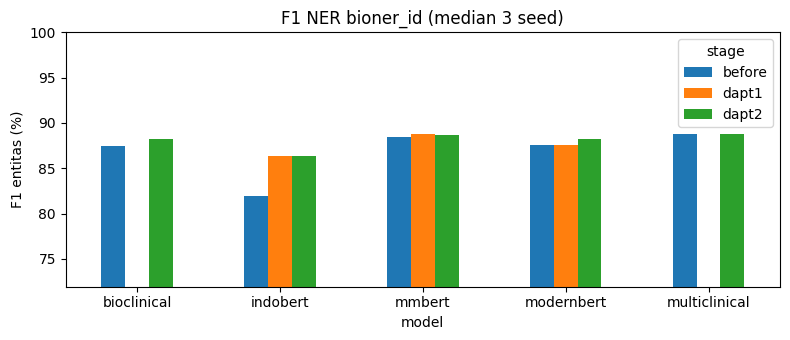

In [24]:
CHOSEN_LR = {os.path.basename(p)[3:-5]: jload(p)["lr"] for p in glob.glob(f"{RES}/ner/lr_*.json")}
NER = pd.DataFrame([jload(p) for p in glob.glob(f"{RES}/ner/*.json") if not os.path.basename(p).startswith("lr_")])
if len(NER):
    NER = NER[NER.apply(lambda r: r["lr"] == CHOSEN_LR.get(r["model"]), axis=1)].copy()
    NER_MED = NER.groupby(["model", "stage"]).agg(test_f1_median=("test_f1", "median"), test_f1_std=("test_f1", "std"),
                                                  val_f1_median=("val_f1", "median"), n_seed=("seed", "count")).round(4)
    NER_TAB = (100 * NER_MED["test_f1_median"].unstack("stage")).round(2)
    NER_TAB = NER_TAB[[s for s in STAGES_ALL if s in NER_TAB.columns]]
    for st in [s for s in ["dapt1", "dapt2"] if s in NER_TAB.columns]:
        NER_TAB[f"Δ_{st}"] = (NER_TAB[st] - NER_TAB["before"]).round(2)
    NER_TAB.to_csv(f"{REP}/tables/ner_f1.csv"); NER_MED.to_csv(f"{REP}/tables/ner_detail.csv")
    print("F1 test (median 3 seed, dalam persen), Δ dalam poin F1:"); display(NER_TAB)
    print("Detail (std antar seed, jumlah seed):"); display(NER_MED)

    rows = []
    for key, g in NER.groupby("model"):
        b = g[g.stage == "before"].set_index("seed")["test_f1"]
        for st in [s for s in ["dapt1", "dapt2"] if s in set(g.stage)]:
            d = (g[g.stage == st].set_index("seed")["test_f1"] - b).dropna()
            rows.append({"model": key, "tahap": st, "rata_Δ_poin": round(100 * d.mean(), 2),
                         "std_Δ_poin": round(100 * d.std(), 2), "seed_menang": f"{int((d > 0).sum())}/{len(d)}"})
    CONSIST = pd.DataFrame(rows); CONSIST.to_csv(f"{REP}/tables/ner_konsistensi.csv", index=False)
    print("Konsistensi per seed:"); display(CONSIST)

    cols = [c for c in STAGES_ALL if c in NER_TAB.columns]
    ax = NER_TAB[cols].plot.bar(figsize=(8, 3.5), title="F1 NER bioner_id (median 3 seed)")
    ax.set_ylabel("F1 entitas (%)"); ax.set_ylim(max(0, NER_TAB[cols].min().min() - 10), 100); plt.xticks(rotation=0)
    plt.tight_layout(); plt.savefig(f"{REP}/figures/ner_before_after.png", dpi=150); plt.show()
else:
    print("Belum ada hasil NER.")

**Interpretasi:** `[Isi: (1) model mana yang F1-nya tertinggi sebelum dan sesudah DAPT? (2) berapa poin kenaikannya, dan apakah lebih besar dari std antar seed? (3) berapa seed yang menang? (4) apakah tahap 2 menambah dibanding tahap 1? (5) RQ2: apakah IndoBERT tetap unggul dari keluarga ModernBERT setelah DAPT? Sebagai gambaran kasar, paper asli bioner_id melaporkan F1 0,7691 dengan model berbasis XLM-R, tapi cara rata-rata F1-nya tidak disebut, jadi tidak bisa dibandingkan langsung.]`

### 5.3 Model umum vs model klinis (RQ5)

Setiap pasangan memakai tokenizer yang sama, jadi selisihnya hanya berasal dari bekal klinis.

| Kolom | Pertanyaan yang dijawab |
|---|---|
| `bekal_klinis_before` | Apakah ilmu klinis (Inggris atau multibahasa) terbawa ke NER medis Indonesia tanpa latihan tambahan? |
| `Δ_DAPT_umum`, `Δ_DAPT_klinis` | Apakah DAPT bahasa Indonesia masih menambah, termasuk di atas model klinis? |
| `bekal_klinis_dapt2` | Setelah sama-sama DAPT, apakah bekal klinis masih berguna? |

In [25]:
if len(NER):
    rows = []
    for umum, klinis in CFG["pairs"]:
        if umum in NER_TAB.index and klinis in NER_TAB.index:
            g = lambda k, s: NER_TAB.loc[k, s] if s in NER_TAB.columns else np.nan
            rows.append({"pasangan": f"{umum} vs {klinis}",
                         "umum_before": g(umum, "before"), "klinis_before": g(klinis, "before"),
                         "umum_dapt2": g(umum, "dapt2"), "klinis_dapt2": g(klinis, "dapt2"),
                         "bekal_klinis_before": round(g(klinis, "before") - g(umum, "before"), 2),
                         "bekal_klinis_dapt2": round(g(klinis, "dapt2") - g(umum, "dapt2"), 2),
                         "Δ_DAPT_umum": round(g(umum, "dapt2") - g(umum, "before"), 2),
                         "Δ_DAPT_klinis": round(g(klinis, "dapt2") - g(klinis, "before"), 2)})
    if "indobert" in NER_TAB.index:
        rows.append({"pasangan": "indobert (tanpa kembaran klinis)", "umum_before": NER_TAB.loc["indobert", "before"],
                     "umum_dapt2": NER_TAB.loc["indobert"].get("dapt2", np.nan),
                     "Δ_DAPT_umum": NER_TAB.loc["indobert"].get("Δ_dapt2", np.nan)})
    FAMILY = pd.DataFrame(rows); FAMILY.to_csv(f"{REP}/tables/keluarga_model.csv", index=False)
    display(FAMILY)

,pasangan,umum_before,klinis_before,umum_dapt2,klinis_dapt2,bekal_klinis_before,bekal_klinis_dapt2,Δ_DAPT_umum,Δ_DAPT_klinis
0,modernbert vs bioclinical,87.53,87.49,88.28,88.25,-0.04,-0.03,0.75,0.76
1,mmbert vs multiclinical,88.48,88.75,88.63,88.77,0.27,0.14,0.15,0.02
2,indobert (tanpa kembaran klinis),81.94,NaN,86.35,NaN,NaN,NaN,4.41,NaN


**Interpretasi:** `[Isi: apakah BioClinical lebih baik dari ModernBERT sebelum DAPT (ilmu klinis Inggris terbawa)? Apakah selisih itu mengecil atau hilang setelah DAPT? Hal yang sama untuk mmBERT vs MultiClinical. Model mana yang terbaik secara keseluruhan: bahasa asli (IndoBERT) atau bekal medis?]`

### 5.4 F1 per jenis entitas dan analisis error

Dua analisis: (1) F1 `DISO` dan `ANAT` sebelum dan sesudah DAPT, dan (2) contoh potongan test yang berubah dari salah menjadi benar, dan sebaliknya, untuk model dengan F1 `dapt2` tertinggi.

In [26]:
if len(NER):
    pt = pd.DataFrame([{"model": r["model"], "stage": r["stage"], "entitas": t, "f1": f}
                       for _, r in NER.iterrows() for t, f in r["per_type"].items()])
    PER_TYPE = (100 * pt.groupby(["model", "entitas", "stage"])["f1"].median().unstack("stage")).round(2)
    PER_TYPE = PER_TYPE[[s for s in STAGES_ALL if s in PER_TYPE.columns]]
    if {"before", "dapt2"} <= set(PER_TYPE.columns):
        PER_TYPE["Δ_dapt2"] = (PER_TYPE["dapt2"] - PER_TYPE["before"]).round(2)
    PER_TYPE.to_csv(f"{REP}/tables/ner_per_entitas.csv")
    display(PER_TYPE)

stage                  before  dapt1  dapt2  Δ_dapt2
model         entitas                               
bioclinical   ANAT      87.47    NaN  88.13     0.66
              DISO      87.52    NaN  88.30     0.78
indobert      ANAT      84.92  86.91  86.92     2.00
              DISO      80.75  86.08  86.14     5.39
mmbert        ANAT      88.45  89.01  88.01    -0.44
              DISO      88.58  88.71  88.83     0.25
modernbert    ANAT      87.64  87.53  88.21     0.57
              DISO      87.53  87.67  88.31     0.78
multiclinical ANAT      88.85    NaN  88.72    -0.13
              DISO      88.54    NaN  88.77     0.23

Sel berikut membandingkan prediksi seed 42 sebelum dan sesudah DAPT pada potongan test yang sama, untuk model dengan F1 `dapt2` tertinggi. **Diperbaiki** artinya `before` salah dan `dapt2` benar di seluruh potongan; **dirusak** kebalikannya. Untuk melihat model lain, panggil `show_changes("nama_model")`.

In [27]:
def show_changes(key, after_stage="dapt2", k=5):
    lr = CHOSEN_LR.get(key)
    f = lambda st: f"{RES}/ner/{key}_{st}_lr{lr:g}_s{CFG['seed']}.json"
    if lr is None or not (os.path.exists(f("before")) and os.path.exists(f(after_stage))):
        print("Hasil belum lengkap untuk", key); return
    b, a = jload(f("before")), jload(f(after_stage))
    toks = ner_dataset(key)["test"]["tokens"]
    trio = list(zip(b["test_true"], b["test_pred"], a["test_pred"]))
    fixed = [i for i, (t, pb, pa) in enumerate(trio) if pb != t and pa == t]
    broke = [i for i, (t, pb, pa) in enumerate(trio) if pb == t and pa != t]
    print(f"{key}: diperbaiki DAPT = {len(fixed)}, dirusak DAPT = {len(broke)} (dari {len(toks)} potongan test)")
    for title, idxs in [("DIPERBAIKI", fixed[:k]), ("DIRUSAK", broke[:k])]:
        print(f"\n--- {title} ---")
        for i in idxs:
            ents = lambda tags: [(w, t) for w, t in zip(toks[i], tags) if t != "O"]
            print("Teks  :", " ".join(toks[i])[:220])
            print("  benar :", ents(b["test_true"][i])); print("  before:", ents(b["test_pred"][i])); print("  after :", ents(a["test_pred"][i]))

if len(NER) and "dapt2" in NER_TAB.columns and NER_TAB["dapt2"].notna().any():
    show_changes(NER_TAB["dapt2"].idxmax())

multiclinical: diperbaiki DAPT = 6, dirusak DAPT = 4 (dari 428 potongan test)

--- DIPERBAIKI ---
Teks  : malam , Sakit pada saat buang air kecil umumnya sering disebabkan karena infeksi saluran kemih ( ISK).Baca topik terkait : infeksi saluran kemih Penyebab lain yang dapat menimbulkan keluhan serupa seperti : Infeksi kandu
  benar : [('Sakit', 'B-DISO'), ('pada', 'I-DISO'), ('saat', 'I-DISO'), ('buang', 'I-DISO'), ('air', 'I-DISO'), ('kecil', 'I-DISO'), ('infeksi', 'B-DISO'), ('saluran', 'I-DISO'), ('kemih', 'I-DISO'), ('infeksi', 'B-DISO'), ('saluran', 'I-DISO'), ('kemih', 'I-DISO'), ('Infeksi', 'B-DISO'), ('kandung', 'I-DISO'), ('kemih', 'I-DISO'), ('Batu', 'B-DISO'), ('saluran', 'I-DISO'), ('kemih', 'I-DISO'), ('Batu', 'B-DISO'), ('ginjal', 'I-DISO'), ('Peradangan', 'B-DISO'), ('rongga', 'I-DISO'), ('panggul', 'I-DISO'), ('buang', 'B-DISO'), ('air', 'B-DISO'), ('kecil', 'B-DISO')]
  before: [('Sakit', 'B-DISO'), ('pada', 'I-DISO'), ('saat', 'I-DISO'), ('buang', 'I-DISO'), ('air', 

**Interpretasi:** `[Isi: entitas mana yang paling terbantu DAPT (DISO atau ANAT)? Dari contoh: kesalahan apa yang diperbaiki (istilah medis, singkatan, batas entitas, typo) dan kesalahan apa yang muncul? Kaitkan dengan label janggal di bagian 3.2 kalau ada.]`

### 5.5 Biaya komputasi (RQ3)

Diukur: parameter, ukuran checkpoint, jam GPU dan token per detik DAPT, VRAM puncak, rata-rata waktu fine-tuning NER, dan kecepatan inferensi (ribu token per detik) untuk input 512 token tetap dan bervariasi.

GPU: NVIDIA A100-SXM4-40GB


,model,param_juta,badan_juta,token_per_kata,dapt1_jam_gpu,dapt1_token_per_detik,dapt1_vram_GB,dapt2_jam_gpu,dapt2_token_per_detik,dapt2_vram_GB,checkpoint_MB,ner_detik_rata2,infer_tetap_kTok/s,infer_bervariasi_kTok/s
0,indobert,124.5,86.1,1.234,0.063,85026.1,6.41,0.025,82338.2,6.41,498.9,186.9,602.7,272.9
1,mmbert,307.8,111.2,1.464,0.161,39039.4,12.08,0.059,41413.0,10.15,1265.6,420.9,284.4,147.3
2,modernbert,149.7,111.0,2.643,0.224,49266.9,5.98,0.090,49485.3,5.59,602.2,277.2,290.7,147.5
3,bioclinical,149.7,111.0,2.643,0.225,49196.5,5.98,0.090,49340.4,5.59,602.2,277.3,290.1,147.2
4,multiclinical,307.8,111.2,1.464,0.162,38989.6,12.08,0.059,41424.9,10.15,1265.6,319.9,290.9,147.1


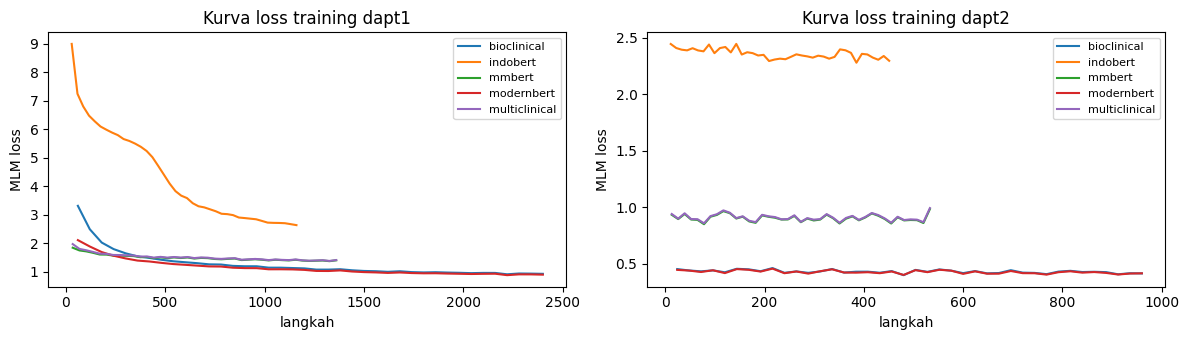

In [28]:
@torch.no_grad()
def bench_inference(path, variable=False, n=512, bs=32, seed=0):
    model = AutoModel.from_pretrained(path).to(DEVICE).eval()
    g = torch.Generator().manual_seed(seed)
    lens = (torch.normal(256.0, 64.0, (n,), generator=g).clamp(16, 512).long() if variable else torch.full((n,), 512))
    ids = torch.randint(100, 16000, (n, 512), generator=g)
    mask = (torch.arange(512)[None, :] < lens[:, None]).long()
    for i in range(0, 2 * bs, bs):   # pemanasan
        with torch.autocast("cuda", dtype=DTYPE, enabled=HAS_GPU):
            model(input_ids=ids[i:i + bs].to(DEVICE), attention_mask=mask[i:i + bs].to(DEVICE))
    if HAS_GPU: torch.cuda.synchronize()
    t0 = time.time()
    for i in range(0, n, bs):
        with torch.autocast("cuda", dtype=DTYPE, enabled=HAS_GPU):
            model(input_ids=ids[i:i + bs].to(DEVICE), attention_mask=mask[i:i + bs].to(DEVICE))
    if HAS_GPU: torch.cuda.synchronize()
    secs = time.time() - t0
    del model; free()
    return round(int(mask.sum()) / secs / 1000, 1)

mi = pd.read_csv(f"{RES}/model_info.csv").set_index("model") if os.path.exists(f"{RES}/model_info.csv") else pd.DataFrame()
ts = TOK_STATS.set_index("model") if "TOK_STATS" in globals() else pd.DataFrame()
cost_rows = []
for key in CFG["models"]:
    row = {"model": key}
    if key in mi.index:
        row.update({"param_juta": mi.loc[key, "param_juta"], "badan_juta": mi.loc[key, "badan_juta"]})
    if key in ts.index:
        row["token_per_kata"] = ts.loc[key, "token_per_kata"]
    for st in ["dapt1", "dapt2"]:
        p = f"{RES}/dapt_{key}_{st}.json"
        if os.path.exists(p):
            s = jload(p)
            row.update({f"{st}_jam_gpu": s["jam_gpu"], f"{st}_token_per_detik": s["token_per_detik"], f"{st}_vram_GB": s["peak_vram_GB"]})
    ck = model_path(key, "dapt1")
    if os.path.isdir(ck):
        row["checkpoint_MB"] = round(sum(os.path.getsize(f) for f in glob.glob(f"{ck}/*")) / 1e6, 1)
    if len(NER) and key in set(NER.model):
        row["ner_detik_rata2"] = round(NER[NER.model == key]["detik"].mean(), 1)
    if CFG["RUN_INFERENCE_BENCH"] and key in CFG["run_models"]:
        bp = f"{RES}/infer_{key}.json"
        if not os.path.exists(bp):
            jsave({"tetap_kTok_s": bench_inference(CFG["models"][key]),
                   "bervariasi_kTok_s": bench_inference(CFG["models"][key], variable=True), "gpu": GPU_NAME}, bp)
        b = jload(bp); row.update({"infer_tetap_kTok/s": b["tetap_kTok_s"], "infer_bervariasi_kTok/s": b["bervariasi_kTok_s"]})
    cost_rows.append(row)
COST = pd.DataFrame(cost_rows); COST.to_csv(f"{REP}/tables/biaya.csv", index=False)
print("GPU:", GPU_NAME); display(COST)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, st in zip(axes, ["dapt1", "dapt2"]):
    for p in sorted(glob.glob(f"{RES}/dapt_log_*_{st}.csv")):
        log = pd.read_csv(p)
        if "loss" in log:
            log = log.dropna(subset=["loss"])
            ax.plot(log["step"], log["loss"], label=os.path.basename(p)[len("dapt_log_"):-len(f"_{st}.csv")])
    ax.set_title(f"Kurva loss training {st}"); ax.set_xlabel("langkah"); ax.set_ylabel("MLM loss"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{REP}/figures/kurva_loss_dapt.png", dpi=150); plt.show()

**Interpretasi:** `[Isi: berapa jam GPU dan VRAM tiap model? Apakah model dengan token per kata tinggi juga paling lama dilatih? Model mana yang paling efisien (kenaikan F1 per jam GPU)? Catatan: diukur di GPU Colab, tidak bisa disamakan dengan paper.]`

### 5.6 Model final dan contoh inferensi

Model final dipilih dari **F1 validation (median seed)** di antara semua (model, tahap), lalu dilatih ulang dengan seed 42 dan disimpan di `ckpt/final_ner`. Test tidak dipakai untuk memilih.

In [ ]:
if CFG["RUN_FINAL"] and len(NER):
    best = NER_MED.reset_index().sort_values("val_f1_median", ascending=False).iloc[0]
    key, stage = best["model"], best["stage"]
    save_dir = f"{CKPT}/final_ner"
    if not has_ckpt(save_dir):
        ner_run(key, stage, CHOSEN_LR[key], CFG["seed"], save_to=save_dir)
    FINAL = {"model": key, "stage": stage, "lr": CHOSEN_LR[key], "path": save_dir,
             "val_f1_median": float(best["val_f1_median"]), "test_f1_median": float(best["test_f1_median"])}
    jsave(FINAL, f"{REP}/model_final.json")
    print(FINAL)

    ner_pipe = pipeline("token-classification", model=save_dir, aggregation_strategy="simple", device=0 if HAS_GPU else -1)
    contoh = "Diare yang disertai nyeri perut bagian bawah dapat disebabkan oleh infeksi pada usus besar."
    hasil = [{"entitas": e["entity_group"], "teks": e["word"], "skor": round(float(e["score"]), 3)} for e in ner_pipe(contoh)]
    print(contoh); display(pd.DataFrame(hasil))
    jsave({"input": contoh, "output": hasil}, f"{REP}/contoh_inferensi.json")

### 5.7 Ringkasan angka per RQ

Sel ini mengumpulkan angka kunci dari tabel-tabel di atas untuk membantu menulis bagian 6.

In [30]:
print("=== RQ1: perubahan MLM loss medis (%) dan F1 NER (poin) setelah dapt2 ===")
if len(MLM) and "Δ%_dapt2" in MLM_MEDIS: print(MLM_MEDIS["Δ%_dapt2"].to_string())
if len(NER) and "Δ_dapt2" in NER_TAB: print(NER_TAB["Δ_dapt2"].to_string())
print("\n=== RQ2: F1 sebelum dan sesudah, diurutkan ===")
if len(NER): print(NER_TAB.sort_values(NER_TAB.columns[-1] if "dapt2" not in NER_TAB else "dapt2", ascending=False).to_string())
print("\n=== RQ3: tokenizer dan biaya ===")
print(COST.set_index("model")[[c for c in COST.columns if c in ("token_per_kata", "dapt1_jam_gpu", "dapt2_jam_gpu", "dapt1_vram_GB")]].to_string())
print("\n=== RQ4: perubahan MLM loss Wikipedia (%) ===")
if len(MLM) and "Δ%_dapt2" in MLM_WIKI: print(MLM_WIKI["Δ%_dapt2"].to_string())
print("\n=== RQ5: model umum vs klinis ===")
if len(NER) and "FAMILY" in globals(): print(FAMILY.to_string())

=== RQ1: perubahan MLM loss medis (%) dan F1 NER (poin) setelah dapt2 ===
model
bioclinical     -86.74
indobert        -80.04
mmbert          -37.00
modernbert      -75.74
multiclinical   -41.72
model
bioclinical      0.76
indobert         4.41
mmbert           0.15
modernbert       0.75
multiclinical    0.02

=== RQ2: F1 sebelum dan sesudah, diurutkan ===
stage          before  dapt1  dapt2  Δ_dapt1  Δ_dapt2
model                                                
multiclinical   88.75    NaN  88.77      NaN     0.02
mmbert          88.48  88.74  88.63     0.26     0.15
modernbert      87.53  87.60  88.28     0.07     0.75
bioclinical     87.49    NaN  88.25      NaN     0.76
indobert        81.94  86.32  86.35     4.38     4.41

=== RQ3: tokenizer dan biaya ===
               token_per_kata  dapt1_jam_gpu  dapt1_vram_GB  dapt2_jam_gpu
model                                                                     
indobert                1.234          0.063           6.41          0.025
mmbe

<a id="bagian-6"></a>
## 6. Pembahasan, Keterbatasan, dan Kesimpulan

### 6.1 Jawaban pertanyaan penelitian

**RQ1 (manfaat DAPT):** `[Isi: penurunan MLM loss medis dan perubahan F1 NER per model, beserta konsistensi antar seed.]`

**RQ2 (bahasa asli vs arsitektur modern):** `[Isi: urutan model sebelum dan sesudah DAPT; apakah IndoBERT tetap di atas keluarga ModernBERT?]`

**RQ3 (tokenizer dan biaya):** `[Isi: token per kata, jam GPU, dan kecepatan inferensi; trade-off kualitas dan biaya.]`

**RQ4 (lupa bahasa umum):** `[Isi: perubahan MLM loss Wikipedia; bandingkan dengan CP1 yang tidak mencampur data umum.]`

**RQ5 (model klinis siap pakai):** `[Isi: apakah bekal klinis terbawa ke bahasa Indonesia, dan apakah DAPT masih menambah di atasnya.]`

**Hubungan dengan CP1 dan paper:** `[Isi: apakah pola "DAPT membantu tapi kecil di skala kecil" dari CP1 terulang? Apa yang berbeda karena bahasa?]`

### 6.2 Keterbatasan

1. **Korpus:** jawaban dokter dari konsultasi online, bukan rekam medis rumah sakit. Bekas link yang dihapus dan sebagian template masih tersisa setelah dibersihkan.
2. **Sumber sama:** korpus DAPT dan bioner_id sama-sama dari Alodokter. Kebocoran sudah dicek dengan kecocokan persis dan 8-gram, tapi teks yang diparafrasekan tidak terdeteksi.
3. **Lisensi alodokter-qna:** ketentuan situs untuk data hasil scrape belum jelas; data mentah tidak disebar ulang.
4. **Label bioner_id:** ada pola label janggal (bagian 3.2) yang tidak diubah.
5. **Skala:** sekitar 15 juta kata per tahap; jauh di bawah skala paper.
6. **Konteks:** semua model memakai 512 token; konteks panjang keluarga ModernBERT tidak diuji.
7. **Statistik:** 3 seed dan grid LR NER kecil (2 nilai), dipilih hanya di model `before`.
8. **Model klinis:** MultiClinicalBERT belum punya paper dan tidak dilatih dengan teks Indonesia; BioClinical dan MultiClinical hanya dievaluasi di `before` dan `dapt2`.
9. **Tugas:** hanya satu tugas downstream (NER, dua jenis entitas).
10. `[Tambahkan deviasi lain yang terjadi saat menjalankan notebook.]`

### 6.3 Kesimpulan

1. **Masalah:** encoder umum belum terbiasa dengan teks medis bahasa Indonesia, dan belum ada encoder medis bahasa Indonesia yang dirilis publik (sejauh pencarian kami).
2. **Metode:** resep DAPT dua tahap dari CP1, diterapkan ke lima checkpoint dengan korpus jawaban dokter Indonesia, dievaluasi dengan MLM loss, NER bioner_id, uji lupa, dan biaya.
3. **Hasil penting:** `[Isi]`
4. **Pengembangan berikutnya:** `[Isi: misalnya entity masking atau TAPT, tugas tambahan (klasifikasi), lebih banyak seed, konteks panjang.]`

<a id="bagian-7"></a>
## 7. Referensi

[1] T. Sounack dkk., "BioClinical ModernBERT: A State-of-the-Art Long-Context Encoder for Biomedical and Clinical NLP," arXiv:2506.10896, 2025.
[2] S. Gururangan dkk., "Don't Stop Pretraining: Adapt Language Models to Domains and Tasks," *ACL*, 2020.
[3] B. Warner dkk., "Smarter, Better, Faster, Longer: A Modern Bidirectional Encoder for Fast, Memory Efficient, and Long Context Finetuning and Inference," arXiv:2412.13663, 2024.
[4] M. Marone dkk., "mmBERT: A Modern Multilingual Encoder with Annealed Language Learning," arXiv:2509.06888, 2025.
[5] B. Wilie dkk., "IndoNLU: Benchmark and Resources for Evaluating Indonesian Natural Language Understanding," *AACL-IJCNLP*, 2020 (IndoBERT).
[6] YLab-Open, MultiClinicalBERT, https://huggingface.co/YLab-Open/MultiClinicalBERT (model card).
[7] Abdillah dkk., "Pengenalan Entitas Biomedis dalam Teks Konsultasi Kesehatan Online Berbahasa Indonesia Berbasis Arsitektur Transformers," *JTIIK*, 2023 (bioner_id).
[8] Juanita, Purwitasari, Purnama, Purnomo, "Doctor's Answer Text Dataset in Indonesian Contains Information on Medical Interview Patterns," Mendeley Data v1, doi:10.17632/p8d5bynh3m.1, 2023.
[9] agufsamudra, alodokter-qna, https://huggingface.co/datasets/agufsamudra/alodokter-qna.
[10] Wikimedia Foundation, Wikipedia bahasa Indonesia, dump 20231101 (`wikimedia/wikipedia`).
[11] H. Nakayama, "seqeval: A Python framework for sequence labeling evaluation," 2018.
[12] T. Wolf dkk., "Transformers: State-of-the-Art Natural Language Processing," *EMNLP: System Demonstrations*, 2020.

### Checklist

- [ ] Nama tim, mentor, dan tanggal sudah diisi
- [ ] Notebook bisa dijalankan ulang dengan **Run all**
- [ ] Audit noise, pembersihan, duplikat, dan cek bocor terdokumentasi (bagian 1), dataset card terisi
- [ ] Statistik tokenizer dan info model terisi (bagian 2)
- [ ] Statistik dan cek label NER terisi (bagian 3)
- [ ] Semua model punya hasil `before`, dan hasil DAPT sesuai `eval_stages` (bagian 4)
- [ ] Semua sel `[Isi ...]` sudah diganti interpretasi berdasarkan output (bagian 1 sampai 5)
- [ ] RQ1 sampai RQ5 dijawab (bagian 6.1), keterbatasan dan deviasi ditulis terbuka (bagian 6.2)